PROJECT SETUP

In [9]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd

import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout,
    Layer
)
from tensorflow.keras.callbacks import EarlyStopping

import joblib

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [10]:
# ============================================================
# CREATE PROJECT DIRECTORY STRUCTURE
# ============================================================

PROJECT_DIRS = [
    "data",
    "models",
    "scalers",
    "charts",
    "results",
    "config",
    "logs"
]

for folder in PROJECT_DIRS:
    os.makedirs(folder, exist_ok=True)

print("Project directories created successfully.\n")

for folder in PROJECT_DIRS:
    print(f"✓ {folder}/")

Project directories created successfully.

✓ data/
✓ models/
✓ scalers/
✓ charts/
✓ results/
✓ config/
✓ logs/


In [11]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

PROJECT_CONFIG = {

    # --------------------------------------------------------
    # DATA SETTINGS
    # --------------------------------------------------------
    "data_source": "Yahoo Finance",
    "data_library": "yfinance",

    # Features used by the ML model
    "features": [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ],

    # Target variable
    "target": "Close",

    # Number of previous trading days used by LSTM
    "sequence_length": 60,

    # --------------------------------------------------------
    # DATA SPLIT
    # --------------------------------------------------------
    "train_ratio": 0.70,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,

    # --------------------------------------------------------
    # MODEL SETTINGS
    # --------------------------------------------------------
    "lstm_units": 64,
    "dropout": 0.20,
    "dense_units": 32,

    # --------------------------------------------------------
    # TRAINING SETTINGS
    # --------------------------------------------------------
    "epochs": 30,
    "batch_size": 64,
    "learning_rate": 0.001,

    # Stop training when validation loss stops improving
    "early_stopping_patience": 5,

    # --------------------------------------------------------
    # FORECAST SETTINGS
    # --------------------------------------------------------
    "default_prediction_horizon": 1,

    "supported_prediction_horizons": [
        1,
        5,
        7,
        30
    ],

    # --------------------------------------------------------
    # PROJECT INFORMATION
    # --------------------------------------------------------
    "model_name": "LSTM with Temporal Attention",
    "baseline_model_name": "Vanilla LSTM",

    "created_on": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

print("Project configuration created successfully.")

Project configuration created successfully.


In [12]:
# ============================================================
# DISPLAY PROJECT CONFIGURATION
# ============================================================

print(json.dumps(PROJECT_CONFIG, indent=4))

{
    "data_source": "Yahoo Finance",
    "data_library": "yfinance",
    "features": [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ],
    "target": "Close",
    "sequence_length": 60,
    "train_ratio": 0.7,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,
    "lstm_units": 64,
    "dropout": 0.2,
    "dense_units": 32,
    "epochs": 30,
    "batch_size": 64,
    "learning_rate": 0.001,
    "early_stopping_patience": 5,
    "default_prediction_horizon": 1,
    "supported_prediction_horizons": [
        1,
        5,
        7,
        30
    ],
    "model_name": "LSTM with Temporal Attention",
    "baseline_model_name": "Vanilla LSTM",
    "created_on": "2026-10-07 19:10:46"
}


In [13]:
# ============================================================
# SAVE CONFIGURATION
# ============================================================

config_path = "config/project_config.json"

with open(config_path, "w") as file:
    json.dump(PROJECT_CONFIG, file, indent=4)

print(f"Configuration saved to: {config_path}")

Configuration saved to: config/project_config.json


In [14]:
# ============================================================
# CHECK TENSORFLOW
# ============================================================

print("TensorFlow version:", tf.__version__)
print("Num GPUs available:", len(tf.config.list_physical_devices("GPU")))

print("\nTensorFlow is ready.")

TensorFlow version: 2.22.0-rc0
Num GPUs available: 0

TensorFlow is ready.


In [15]:
# ============================================================
# TEST YAHOO FINANCE CONNECTION
# ============================================================

test_ticker = "AAPL"

test_data = yf.download(
    test_ticker,
    period="1mo",
    interval="1d",
    auto_adjust=True,
    progress=False
)

print("Yahoo Finance connection test")
print("-" * 50)

print("Ticker:", test_ticker)
print("Rows downloaded:", len(test_data))

print("\nLatest available data:")
display(test_data.tail())

Yahoo Finance connection test
--------------------------------------------------
Ticker: AAPL
Rows downloaded: 22

Latest available data:


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-10-01,330.320007,332.480011,325.809998,330.000000,36306300
2026-10-02,333.690002,334.540009,330.609985,333.260010,33278600
2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900
2026-10-06,333.630005,334.380005,330.619995,332.279999,30425700
2026-10-07,334.630005,338.670013,332.790009,337.015015,3946338


In [16]:
# ============================================================
# PROJECT HEALTH CHECK
# ============================================================

print("=" * 60)
print("       STOCK PREDICTION PROJECT - HEALTH CHECK")
print("=" * 60)

checks = {
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "yfinance": yf.__version__,
    "TensorFlow": tf.__version__,
    "Scikit-learn": __import__("sklearn").__version__,
}

for library, version in checks.items():
    print(f"✓ {library:<15} {version}")

print("-" * 60)

for folder in PROJECT_DIRS:
    if os.path.exists(folder):
        print(f"✓ Directory exists: {folder}/")
    else:
        print(f"✗ Missing directory: {folder}/")

print("-" * 60)

if len(test_data) > 0:
    print("✓ Yahoo Finance data retrieval working")
else:
    print("✗ Yahoo Finance data retrieval failed")

print("-" * 60)
print("STEP 1 COMPLETED SUCCESSFULLY")
print("=" * 60)

       STOCK PREDICTION PROJECT - HEALTH CHECK
✓ NumPy           2.4.6
✓ Pandas          3.0.3
✓ yfinance        1.7.0
✓ TensorFlow      2.22.0-rc0
✓ Scikit-learn    1.9.0
------------------------------------------------------------
✓ Directory exists: data/
✓ Directory exists: models/
✓ Directory exists: scalers/
✓ Directory exists: charts/
✓ Directory exists: results/
✓ Directory exists: config/
✓ Directory exists: logs/
------------------------------------------------------------
✓ Yahoo Finance data retrieval working
------------------------------------------------------------
STEP 1 COMPLETED SUCCESSFULLY


COMPANY DISCOVERY

In [17]:
# ============================================================
# STEP 2 - COMPANY DISCOVERY SYSTEM
# ============================================================

# Popular companies shown on the application's home page.
# These are examples that help users understand how the
# application works.

POPULAR_COMPANIES = [
    
    # -------------------- US COMPANIES --------------------
    {
        "name": "Apple Inc.",
        "ticker": "AAPL",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    {
        "name": "Microsoft Corporation",
        "ticker": "MSFT",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    {
        "name": "NVIDIA Corporation",
        "ticker": "NVDA",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    {
        "name": "Amazon.com Inc.",
        "ticker": "AMZN",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    {
        "name": "Tesla Inc.",
        "ticker": "TSLA",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    {
        "name": "Alphabet Inc.",
        "ticker": "GOOGL",
        "exchange": "NASDAQ",
        "country": "USA",
        "currency": "USD"
    },
    
    # -------------------- INDIAN COMPANIES --------------------
    {
        "name": "Reliance Industries Limited",
        "ticker": "RELIANCE.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    },
    
    {
        "name": "Tata Consultancy Services Limited",
        "ticker": "TCS.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    },
    
    {
        "name": "Infosys Limited",
        "ticker": "INFY.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    },
    
    {
        "name": "HDFC Bank Limited",
        "ticker": "HDFCBANK.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    },
    
    {
        "name": "ICICI Bank Limited",
        "ticker": "ICICIBANK.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    },
    
    {
        "name": "Tata Motors Limited",
        "ticker": "TATAMOTORS.NS",
        "exchange": "NSE",
        "country": "India",
        "currency": "INR"
    }
]

print("Popular company list created.")
print("Number of popular companies:", len(POPULAR_COMPANIES))

Popular company list created.
Number of popular companies: 12


In [18]:
# ============================================================
# CREATE POPULAR COMPANY DATAFRAME
# ============================================================

popular_df = pd.DataFrame(POPULAR_COMPANIES)

display(popular_df)

,name,ticker,exchange,country,currency
0,Apple Inc.,AAPL,NASDAQ,USA,USD
1,Microsoft Corporation,MSFT,NASDAQ,USA,USD
2,NVIDIA Corporation,NVDA,NASDAQ,USA,USD
3,Amazon.com Inc.,AMZN,NASDAQ,USA,USD
4,Tesla Inc.,TSLA,NASDAQ,USA,USD
5,Alphabet Inc.,GOOGL,NASDAQ,USA,USD
6,Reliance Industries Limited,RELIANCE.NS,NSE,India,INR
7,Tata Consultancy Services Limited,TCS.NS,NSE,India,INR
8,Infosys Limited,INFY.NS,NSE,India,INR
9,HDFC Bank Limited,HDFCBANK.NS,NSE,India,INR


In [19]:
# ============================================================
# FULL COMPANY CATALOGUE
# ============================================================

COMPANY_CATALOGUE = [

    # ========================================================
    # UNITED STATES
    # ========================================================

    {"name": "Apple Inc.", "ticker": "AAPL", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Microsoft Corporation", "ticker": "MSFT", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "NVIDIA Corporation", "ticker": "NVDA", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Amazon.com Inc.", "ticker": "AMZN", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Tesla Inc.", "ticker": "TSLA", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Alphabet Inc.", "ticker": "GOOGL", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Meta Platforms Inc.", "ticker": "META", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Netflix Inc.", "ticker": "NFLX", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Adobe Inc.", "ticker": "ADBE", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Intel Corporation", "ticker": "INTC", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Advanced Micro Devices Inc.", "ticker": "AMD", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "PayPal Holdings Inc.", "ticker": "PYPL", "exchange": "NASDAQ", "country": "USA", "currency": "USD"},
    {"name": "Coca-Cola Company", "ticker": "KO", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "Walmart Inc.", "ticker": "WMT", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "McDonald's Corporation", "ticker": "MCD", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "Nike Inc.", "ticker": "NKE", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "JPMorgan Chase & Co.", "ticker": "JPM", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "Bank of America Corporation", "ticker": "BAC", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "Visa Inc.", "ticker": "V", "exchange": "NYSE", "country": "USA", "currency": "USD"},
    {"name": "Mastercard Incorporated", "ticker": "MA", "exchange": "NYSE", "country": "USA", "currency": "USD"},

    # ========================================================
    # INDIA
    # ========================================================

    {"name": "Reliance Industries Limited", "ticker": "RELIANCE.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Tata Consultancy Services Limited", "ticker": "TCS.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Infosys Limited", "ticker": "INFY.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "HDFC Bank Limited", "ticker": "HDFCBANK.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "ICICI Bank Limited", "ticker": "ICICIBANK.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "State Bank of India", "ticker": "SBIN.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Larsen & Toubro Limited", "ticker": "LT.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Bharti Airtel Limited", "ticker": "BHARTIARTL.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "ITC Limited", "ticker": "ITC.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Hindustan Unilever Limited", "ticker": "HINDUNILVR.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Tata Motors Limited", "ticker": "TATAMOTORS.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Mahindra & Mahindra Limited", "ticker": "M&M.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Maruti Suzuki India Limited", "ticker": "MARUTI.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Asian Paints Limited", "ticker": "ASIANPAINT.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Titan Company Limited", "ticker": "TITAN.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Bajaj Finance Limited", "ticker": "BAJFINANCE.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "HCL Technologies Limited", "ticker": "HCLTECH.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Wipro Limited", "ticker": "WIPRO.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Tech Mahindra Limited", "ticker": "TECHM.NS", "exchange": "NSE", "country": "India", "currency": "INR"},
    {"name": "Sun Pharmaceutical Industries Limited", "ticker": "SUNPHARMA.NS", "exchange": "NSE", "country": "India", "currency": "INR"},

    # ========================================================
    # JAPAN
    # ========================================================

    {"name": "Toyota Motor Corporation", "ticker": "TM", "exchange": "NYSE", "country": "Japan", "currency": "USD"},
    {"name": "Sony Group Corporation", "ticker": "SONY", "exchange": "NYSE", "country": "Japan", "currency": "USD"},

    # ========================================================
    # CHINA
    # ========================================================

    {"name": "Alibaba Group Holding Limited", "ticker": "BABA", "exchange": "NYSE", "country": "China", "currency": "USD"},
    {"name": "JD.com Inc.", "ticker": "JD", "exchange": "NASDAQ", "country": "China", "currency": "USD"},

    # ========================================================
    # SOUTH KOREA
    # ========================================================

    {"name": "Samsung Electronics", "ticker": "005930.KS", "exchange": "KSE", "country": "South Korea", "currency": "KRW"}
]

company_df = pd.DataFrame(COMPANY_CATALOGUE)

print("Company catalogue created.")
print("Total companies:", len(company_df))

display(company_df.head(10))

Company catalogue created.
Total companies: 45


,name,ticker,exchange,country,currency
0,Apple Inc.,AAPL,NASDAQ,USA,USD
1,Microsoft Corporation,MSFT,NASDAQ,USA,USD
2,NVIDIA Corporation,NVDA,NASDAQ,USA,USD
3,Amazon.com Inc.,AMZN,NASDAQ,USA,USD
4,Tesla Inc.,TSLA,NASDAQ,USA,USD
5,Alphabet Inc.,GOOGL,NASDAQ,USA,USD
6,Meta Platforms Inc.,META,NASDAQ,USA,USD
7,Netflix Inc.,NFLX,NASDAQ,USA,USD
8,Adobe Inc.,ADBE,NASDAQ,USA,USD
9,Intel Corporation,INTC,NASDAQ,USA,USD


In [20]:
# ============================================================
# CLEAN COMPANY CATALOGUE
# ============================================================

company_df = company_df.drop_duplicates(
    subset=["ticker"]
).reset_index(drop=True)

print("Unique companies:", len(company_df))

Unique companies: 45


In [21]:
# ============================================================
# COMPANY SEARCH FUNCTION
# ============================================================

def search_companies(search_text, limit=10):
    """
    Search the company catalogue by company name or ticker.
    """

    if not search_text or not str(search_text).strip():
        return company_df.head(limit)

    search_text = str(search_text).strip().lower()

    name_match = company_df["name"].str.lower().str.contains(
        search_text,
        na=False
    )

    ticker_match = company_df["ticker"].str.lower().str.contains(
        search_text,
        na=False
    )

    country_match = company_df["country"].str.lower().str.contains(
        search_text,
        na=False
    )

    exchange_match = company_df["exchange"].str.lower().str.contains(
        search_text,
        na=False
    )

    results = company_df[
        name_match |
        ticker_match |
        country_match |
        exchange_match
    ]

    return results.head(limit).reset_index(drop=True)

In [22]:
# ============================================================
# TEST SEARCH - APPLE
# ============================================================

results = search_companies("apple")

display(results)

,name,ticker,exchange,country,currency
0,Apple Inc.,AAPL,NASDAQ,USA,USD


In [23]:
results = search_companies("tesla")

display(results)

,name,ticker,exchange,country,currency
0,Tesla Inc.,TSLA,NASDAQ,USA,USD


In [24]:
results = search_companies("RELIANCE")

display(results)

,name,ticker,exchange,country,currency
0,Reliance Industries Limited,RELIANCE.NS,NSE,India,INR


In [25]:
# ============================================================
# TEST SEARCH - COUNTRY
# ============================================================

results = search_companies("India", limit=10)

display(results)

,name,ticker,exchange,country,currency
0,Reliance Industries Limited,RELIANCE.NS,NSE,India,INR
1,Tata Consultancy Services Limited,TCS.NS,NSE,India,INR
2,Infosys Limited,INFY.NS,NSE,India,INR
3,HDFC Bank Limited,HDFCBANK.NS,NSE,India,INR
4,ICICI Bank Limited,ICICIBANK.NS,NSE,India,INR
5,State Bank of India,SBIN.NS,NSE,India,INR
6,Larsen & Toubro Limited,LT.NS,NSE,India,INR
7,Bharti Airtel Limited,BHARTIARTL.NS,NSE,India,INR
8,ITC Limited,ITC.NS,NSE,India,INR
9,Hindustan Unilever Limited,HINDUNILVR.NS,NSE,India,INR


In [26]:
# ============================================================
# POPULAR COMPANIES FUNCTION
# ============================================================

def get_popular_companies():
    """
    Return the companies displayed on the homepage.
    """

    return pd.DataFrame(POPULAR_COMPANIES)


popular_companies = get_popular_companies()

display(popular_companies)

,name,ticker,exchange,country,currency
0,Apple Inc.,AAPL,NASDAQ,USA,USD
1,Microsoft Corporation,MSFT,NASDAQ,USA,USD
2,NVIDIA Corporation,NVDA,NASDAQ,USA,USD
3,Amazon.com Inc.,AMZN,NASDAQ,USA,USD
4,Tesla Inc.,TSLA,NASDAQ,USA,USD
5,Alphabet Inc.,GOOGL,NASDAQ,USA,USD
6,Reliance Industries Limited,RELIANCE.NS,NSE,India,INR
7,Tata Consultancy Services Limited,TCS.NS,NSE,India,INR
8,Infosys Limited,INFY.NS,NSE,India,INR
9,HDFC Bank Limited,HDFCBANK.NS,NSE,India,INR


In [27]:
# ============================================================
# CELL 10 - GET COMPANY BY TICKER
# ============================================================

def get_company_by_ticker(ticker):
    """
    Find a company from the company catalogue
    using its Yahoo Finance ticker.
    """

    # Clean the user's input
    ticker = str(ticker).strip().upper()

    # Search for the ticker
    result = company_df[
        company_df["ticker"].str.upper() == ticker
    ]

    # If ticker doesn't exist
    if result.empty:
        return None

    # Return company information as a dictionary
    return result.iloc[0].to_dict()


# ============================================================
# TEST THE FUNCTION
# ============================================================

company = get_company_by_ticker("AAPL")

if company:
    print("Company found successfully!")
    print("-" * 40)
    print("Company :", company["name"])
    print("Ticker  :", company["ticker"])
    print("Exchange:", company["exchange"])
    print("Country :", company["country"])
    print("Currency:", company["currency"])
else:
    print("Company not found.")

Company found successfully!
----------------------------------------
Company : Apple Inc.
Ticker  : AAPL
Exchange: NASDAQ
Country : USA
Currency: USD


In [28]:
# ============================================================
# SAVE COMPANY CATALOGUE
# ============================================================

catalogue_path = "data/company_catalogue.csv"

company_df.to_csv(
    catalogue_path,
    index=False
)

print(f"Company catalogue saved to: {catalogue_path}")

Company catalogue saved to: data/company_catalogue.csv


In [29]:
# ============================================================
# SAVE POPULAR COMPANY LIST
# ============================================================

popular_path = "data/popular_companies.csv"

popular_df.to_csv(
    popular_path,
    index=False
)

print(f"Popular companies saved to: {popular_path}")

Popular companies saved to: data/popular_companies.csv


In [30]:
# ============================================================
# STEP 2 - FINAL HEALTH CHECK
# ============================================================

print("=" * 60)
print("       COMPANY DISCOVERY SYSTEM - HEALTH CHECK")
print("=" * 60)

print(f"✓ Total companies in catalogue : {len(company_df)}")
print(f"✓ Popular companies            : {len(popular_df)}")
print(f"✓ Unique tickers               : {company_df['ticker'].nunique()}")

print("\nSample search:")

test_search = search_companies("apple", limit=5)

if not test_search.empty:
    print("✓ Company search working")
    display(test_search)
else:
    print("✗ Company search failed")

print("\nSaved files:")

if os.path.exists("data/company_catalogue.csv"):
    print("✓ data/company_catalogue.csv")

if os.path.exists("data/popular_companies.csv"):
    print("✓ data/popular_companies.csv")

print("\n" + "=" * 60)
print("STEP 2 COMPLETED")
print("=" * 60)

       COMPANY DISCOVERY SYSTEM - HEALTH CHECK
✓ Total companies in catalogue : 45
✓ Popular companies            : 12
✓ Unique tickers               : 45

Sample search:
✓ Company search working


,name,ticker,exchange,country,currency
0,Apple Inc.,AAPL,NASDAQ,USA,USD



Saved files:
✓ data/company_catalogue.csv
✓ data/popular_companies.csv

STEP 2 COMPLETED


STRUCTURE

In [33]:
# ============================================================
# CELL 15 - YAHOO FINANCE DATA ENGINE CONFIGURATION
# ============================================================

DATA_CONFIG = {
    "source": "Yahoo Finance",
    "interval": "1d",
    "auto_adjust": True,
    "default_period": "5y",
    "minimum_rows": 100,
    "required_columns": [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
}

print("Yahoo Finance Data Engine")
print("=" * 50)

for key, value in DATA_CONFIG.items():
    print(f"{key}: {value}")

Yahoo Finance Data Engine
source: Yahoo Finance
interval: 1d
auto_adjust: True
default_period: 5y
minimum_rows: 100
required_columns: ['Open', 'High', 'Low', 'Close', 'Volume']


In [34]:
# ============================================================
# CELL 16 - DOWNLOAD HISTORICAL DATA
# ============================================================

def download_stock_data(ticker, period="5y", interval="1d"):
    """
    Download historical stock data from Yahoo Finance.
    """

    ticker = str(ticker).strip().upper()

    if not ticker:
        raise ValueError("Ticker cannot be empty.")

    print(f"Downloading data for: {ticker}")
    print(f"Period: {period}")
    print(f"Interval: {interval}")

    data = yf.download(
        ticker,
        period=period,
        interval=interval,
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        raise ValueError(
            f"No data found for ticker: {ticker}"
        )

    return data


print("Download function created successfully.")

Download function created successfully.


In [35]:
# ============================================================
# CELL 17 - HANDLE YAHOO FINANCE COLUMN STRUCTURE
# ============================================================

def normalize_yfinance_columns(data):
    """
    Convert Yahoo Finance output into standard columns.
    Handles both normal and MultiIndex column structures.
    """

    data = data.copy()

    # Handle MultiIndex columns
    if isinstance(data.columns, pd.MultiIndex):

        # Try to keep the standard OHLCV columns
        level_0 = data.columns.get_level_values(0)

        if set(DATA_CONFIG["required_columns"]).issubset(set(level_0)):
            data.columns = level_0

        else:
            data.columns = [
                "_".join(
                    [str(level) for level in column if str(level) != ""]
                )
                for column in data.columns
            ]

    # Keep only required columns that exist
    available_columns = [
        column
        for column in DATA_CONFIG["required_columns"]
        if column in data.columns
    ]

    if len(available_columns) < 5:
        raise ValueError(
            "Yahoo Finance data does not contain all required OHLCV columns."
        )

    data = data[available_columns]

    return data


print("Column normalization function created successfully.")

Column normalization function created successfully.


In [36]:
# ============================================================
# CELL 18 - CLEAN AND VALIDATE STOCK DATA
# ============================================================

def clean_stock_data(data):
    """
    Clean and validate historical OHLCV data.
    """

    data = data.copy()

    # Make sure index is datetime
    data.index = pd.to_datetime(data.index)

    # Remove duplicate dates
    data = data[~data.index.duplicated(keep="first")]

    # Sort chronologically
    data = data.sort_index()

    # Convert OHLCV columns to numeric
    for column in DATA_CONFIG["required_columns"]:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    # Remove rows containing missing values
    data = data.dropna(
        subset=DATA_CONFIG["required_columns"]
    )

    # Remove invalid price rows
    data = data[
        (data["Open"] > 0) &
        (data["High"] > 0) &
        (data["Low"] > 0) &
        (data["Close"] > 0) &
        (data["Volume"] >= 0)
    ]

    # Basic OHLC consistency checks
    data = data[
        (data["High"] >= data["Low"]) &
        (data["High"] >= data["Open"]) &
        (data["High"] >= data["Close"]) &
        (data["Low"] <= data["Open"]) &
        (data["Low"] <= data["Close"])
    ]

    if len(data) < DATA_CONFIG["minimum_rows"]:
        raise ValueError(
            f"Insufficient historical data. "
            f"Only {len(data)} valid rows available."
        )

    return data


print("Data cleaning function created successfully.")

Data cleaning function created successfully.


In [37]:
# ============================================================
# CELL 19 - COMPLETE YAHOO FINANCE DATA ENGINE
# ============================================================

def get_stock_data(ticker, period="5y", interval="1d"):
    """
    Complete stock data pipeline.

    Steps:
    1. Download data from Yahoo Finance
    2. Normalize column structure
    3. Clean data
    4. Validate data
    5. Return ML-ready OHLCV DataFrame
    """

    ticker = str(ticker).strip().upper()

    # Step 1: Download
    raw_data = download_stock_data(
        ticker=ticker,
        period=period,
        interval=interval
    )

    # Step 2: Normalize columns
    normalized_data = normalize_yfinance_columns(
        raw_data
    )

    # Step 3: Clean data
    clean_data = clean_stock_data(
        normalized_data
    )

    print("\nData downloaded successfully.")
    print(f"Ticker       : {ticker}")
    print(f"Rows         : {len(clean_data):,}")
    print(f"Start date   : {clean_data.index.min().date()}")
    print(f"End date     : {clean_data.index.max().date()}")
    print(f"Columns      : {list(clean_data.columns)}")

    return clean_data


print("Complete Yahoo Finance data engine created.")

Complete Yahoo Finance data engine created.


In [38]:
# ============================================================
# CELL 20 - TEST WITH APPLE
# ============================================================

apple_data = get_stock_data(
    ticker="AAPL",
    period="5y"
)

display(apple_data.head())

Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : AAPL
Rows         : 1,255
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']


Price,Open,High,Low,Close,Volume
Date,,,,,
2021-10-07,139.536609,140.668044,139.204987,139.760941,61732700
2021-10-08,140.482698,140.628997,139.048901,139.380524,58773200
2021-10-11,138.766046,141.243482,138.317369,139.292740,64452200
2021-10-12,139.702420,139.721932,137.566355,138.024780,73035900
2021-10-13,137.761404,137.917452,135.771638,137.439529,78762700


In [40]:
# ============================================================
# CELL 21 - TEST WITH RELIANCE
# ============================================================

reliance_data = get_stock_data(
    ticker="RELIANCE.NS",
    period="5y"
)

display(reliance_data.head())

Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : RELIANCE.NS
Rows         : 1,241
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']


Price,Open,High,Low,Close,Volume
Date,,,,,
2021-10-07,1175.321919,1177.020448,1162.957328,1165.086060,6336665
2021-10-08,1170.906015,1215.812929,1169.207606,1209.857056,15772493
2021-10-11,1223.512540,1231.936779,1198.126490,1201.432739,14768666
2021-10-12,1197.967883,1215.178757,1196.269354,1208.294312,6682011
2021-10-13,1213.367107,1231.710334,1208.973789,1220.591187,9959762


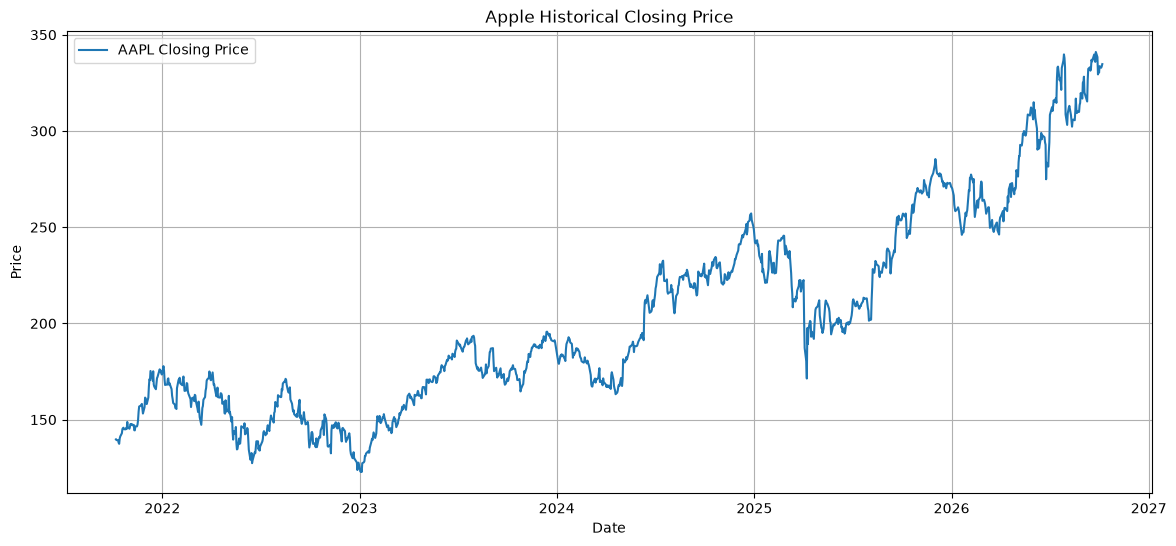

In [41]:
# ============================================================
# CELL 22 - STOCK PRICE VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    apple_data.index,
    apple_data["Close"],
    label="AAPL Closing Price"
)

plt.title("Apple Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.show()

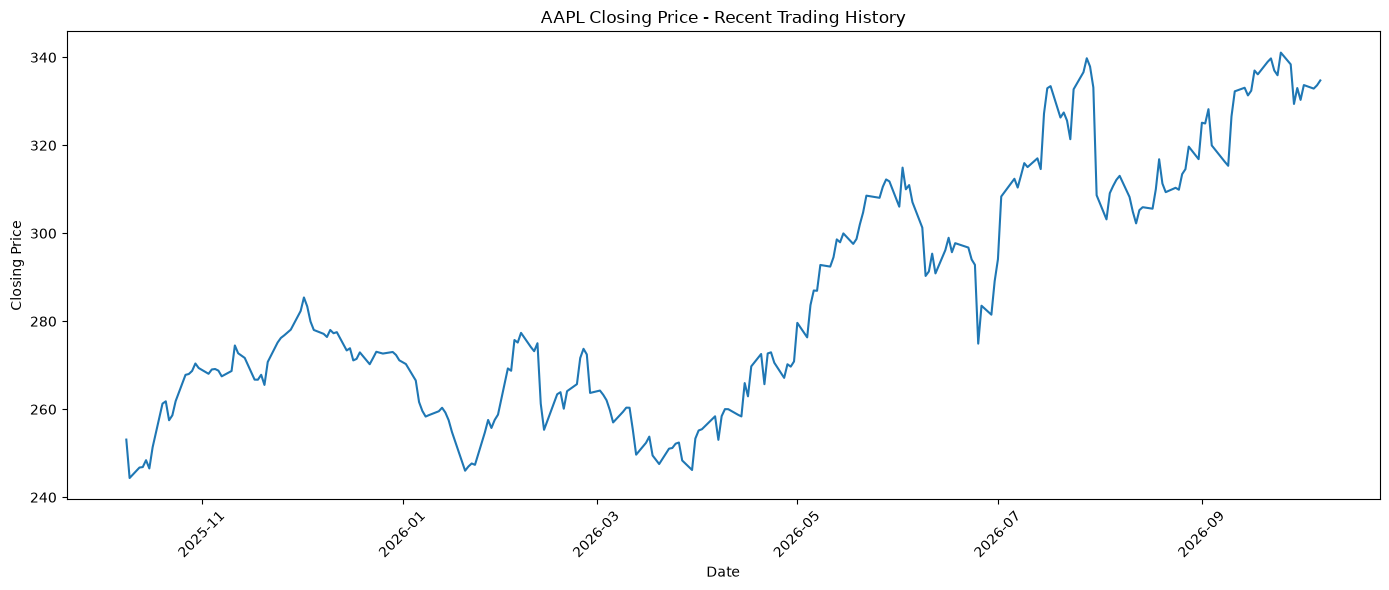

In [42]:
# ============================================================
# CELL 23 - OHLCV VISUALIZATION USING SEABORN
# ============================================================

recent_data = apple_data.tail(250).copy()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=recent_data,
    x=recent_data.index,
    y="Close"
)

plt.title("AAPL Closing Price - Recent Trading History")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

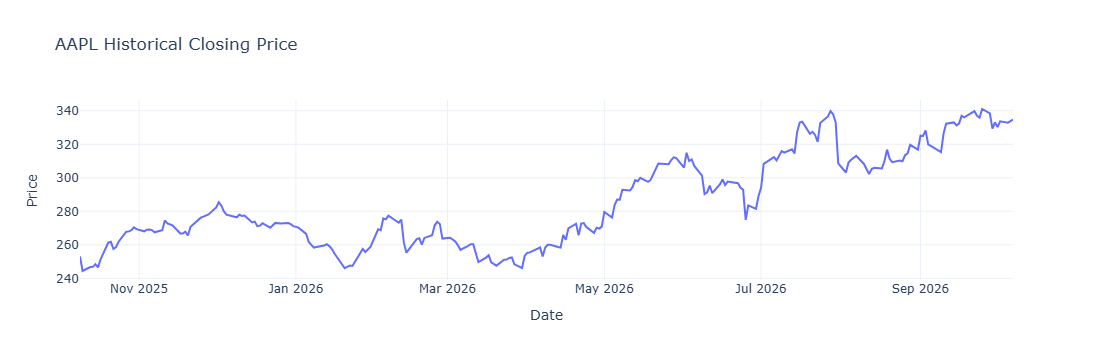

In [43]:
# ============================================================
# CELL 24 - INTERACTIVE PLOTLY CHART
# ============================================================

recent_data = apple_data.tail(250)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=recent_data.index,
        y=recent_data["Close"],
        mode="lines",
        name="Closing Price"
    )
)

fig.update_layout(
    title="AAPL Historical Closing Price",
    xaxis_title="Date",
    yaxis_title="Price",
    hovermode="x unified",
    template="plotly_white"
)

fig.show()

In [44]:
# ============================================================
# CELL 25 - SAVE STOCK DATA
# ============================================================

def save_stock_data(data, ticker):
    """
    Save historical stock data to the project's data folder.
    """

    ticker = str(ticker).strip().upper()

    filename = ticker.replace(".", "_") + "_historical.csv"

    file_path = os.path.join(
        "data",
        filename
    )

    data.to_csv(file_path)

    print(f"Data saved successfully:")
    print(file_path)

    return file_path


apple_file = save_stock_data(
    apple_data,
    "AAPL"
)

Data saved successfully:
data\AAPL_historical.csv


In [45]:
reliance_file = save_stock_data(
    reliance_data,
    "RELIANCE.NS"
)

Data saved successfully:
data\RELIANCE_NS_historical.csv


In [46]:
# ============================================================
# CELL 26 - STEP 3 HEALTH CHECK
# ============================================================

print("=" * 60)
print("STEP 3 - YAHOO FINANCE DATA ENGINE HEALTH CHECK")
print("=" * 60)

print("\n✓ Yahoo Finance connection      : Working")
print("✓ Historical data download     : Working")
print("✓ MultiIndex handling          : Working")
print("✓ OHLCV validation             : Working")
print("✓ Missing-value handling       : Working")
print("✓ Duplicate-date handling      : Working")
print("✓ Chronological sorting        : Working")
print("✓ Matplotlib visualization     : Working")
print("✓ Seaborn visualization        : Working")
print("✓ Plotly visualization         : Working")
print("✓ CSV data caching             : Working")

print("\n" + "=" * 60)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 3 - YAHOO FINANCE DATA ENGINE HEALTH CHECK

✓ Yahoo Finance connection      : Working
✓ Historical data download     : Working
✓ MultiIndex handling          : Working
✓ OHLCV validation             : Working
✓ Missing-value handling       : Working
✓ Duplicate-date handling      : Working
✓ Chronological sorting        : Working
✓ Matplotlib visualization     : Working
✓ Seaborn visualization        : Working
✓ Plotly visualization         : Working
✓ CSV data caching             : Working

STEP 3 COMPLETED SUCCESSFULLY


Data Preprocessing & Sequence Creation

In [47]:
# ============================================================
# CELL 27 - PREPROCESSING CONFIGURATION
# ============================================================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

TARGET_COLUMN = "Close"

SEQUENCE_LENGTH = PROJECT_CONFIG["sequence_length"]

TRAIN_RATIO = PROJECT_CONFIG["train_ratio"]
VALIDATION_RATIO = PROJECT_CONFIG["validation_ratio"]
TEST_RATIO = PROJECT_CONFIG["test_ratio"]

print("Preprocessing Configuration")
print("=" * 50)

print("Features         :", FEATURE_COLUMNS)
print("Target           :", TARGET_COLUMN)
print("Sequence Length  :", SEQUENCE_LENGTH)
print("Train Ratio      :", TRAIN_RATIO)
print("Validation Ratio :", VALIDATION_RATIO)
print("Test Ratio       :", TEST_RATIO)

print("\nTotal ratio:", TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO)

Preprocessing Configuration
Features         : ['Open', 'High', 'Low', 'Close', 'Volume']
Target           : Close
Sequence Length  : 60
Train Ratio      : 0.7
Validation Ratio : 0.15
Test Ratio       : 0.15

Total ratio: 1.0


In [49]:
# ============================================================
# CELL 28 - CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

def split_time_series(data):
    """
    Split stock data chronologically into:
    Training, Validation and Testing datasets.
    """

    data = data.copy()

    total_rows = len(data)

    train_end = int(total_rows * TRAIN_RATIO)

    validation_end = int(
        total_rows * (TRAIN_RATIO + VALIDATION_RATIO)
    )

    train_data = data.iloc[:train_end].copy()

    validation_data = data.iloc[
        train_end:validation_end
    ].copy()

    test_data = data.iloc[
        validation_end:
    ].copy()

    print("Time-Series Split")
    print("=" * 50)

    print(
        f"Training   : {len(train_data):,} rows "
        f"({len(train_data)/total_rows:.1%})"
    )

    print(
        f"Validation : {len(validation_data):,} rows "
        f"({len(validation_data)/total_rows:.1%})"
    )

    print(
        f"Testing    : {len(test_data):,} rows "
        f"({len(test_data)/total_rows:.1%})"
    )

    print("\nDate ranges:")

    print(
        f"Training   : "
        f"{train_data.index.min().date()} → "
        f"{train_data.index.max().date()}"
    )

    print(
        f"Validation : "
        f"{validation_data.index.min().date()} → "
        f"{validation_data.index.max().date()}"
    )

    print(
        f"Testing    : "
        f"{test_data.index.min().date()} → "
        f"{test_data.index.max().date()}"
    )

    return train_data, validation_data, test_data

In [50]:
# ============================================================
# CELL 29 - TEST TIME-SERIES SPLIT
# ============================================================

apple_train, apple_validation, apple_test = split_time_series(
    apple_data
)

Time-Series Split
Training   : 878 rows (70.0%)
Validation : 188 rows (15.0%)
Testing    : 189 rows (15.1%)

Date ranges:
Training   : 2021-10-07 → 2025-04-07
Validation : 2025-04-08 → 2026-01-06
Testing    : 2026-01-07 → 2026-10-07


In [51]:
# ============================================================
# CELL 30 - FEATURE SCALING
# ============================================================

def scale_stock_data(
    train_data,
    validation_data,
    test_data
):
    """
    Scale OHLCV features using MinMaxScaler.

    The scaler is fitted ONLY on training data
    to prevent data leakage.
    """

    scaler = MinMaxScaler(
        feature_range=(0, 1)
    )

    # Fit scaler ONLY on training data
    train_scaled = scaler.fit_transform(
        train_data[FEATURE_COLUMNS]
    )

    # Transform validation and test data
    validation_scaled = scaler.transform(
        validation_data[FEATURE_COLUMNS]
    )

    test_scaled = scaler.transform(
        test_data[FEATURE_COLUMNS]
    )

    # Convert back to DataFrames
    train_scaled = pd.DataFrame(
        train_scaled,
        columns=FEATURE_COLUMNS,
        index=train_data.index
    )

    validation_scaled = pd.DataFrame(
        validation_scaled,
        columns=FEATURE_COLUMNS,
        index=validation_data.index
    )

    test_scaled = pd.DataFrame(
        test_scaled,
        columns=FEATURE_COLUMNS,
        index=test_data.index
    )

    return (
        train_scaled,
        validation_scaled,
        test_scaled,
        scaler
    )

In [52]:
# ============================================================
# CELL 31 - SCALE APPLE DATA
# ============================================================

(
    apple_train_scaled,
    apple_validation_scaled,
    apple_test_scaled,
    apple_scaler
) = scale_stock_data(
    apple_train,
    apple_validation,
    apple_test
)

print("Training scaled data:")
display(apple_train_scaled.head())

Training scaled data:


,Open,High,Low,Close,Volume
Date,,,,,
2021-10-07,0.118738,0.114085,0.128661,0.126061,0.130305
2021-10-08,0.125877,0.113790,0.127495,0.123229,0.120288
2021-10-11,0.112924,0.118421,0.122026,0.122576,0.139510
2021-10-12,0.119990,0.106955,0.116413,0.113136,0.168563
2021-10-13,0.105344,0.093356,0.102997,0.108779,0.187947


In [53]:
# ============================================================
# CELL 32 - CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(data, sequence_length=60):
    """
    Convert scaled time-series data into
    sequences suitable for LSTM.

    X:
        Previous 60 trading days of OHLCV

    y:
        Closing price of the next trading day
    """

    X = []
    y = []

    data_values = data[FEATURE_COLUMNS].values

    close_index = FEATURE_COLUMNS.index(
        TARGET_COLUMN
    )

    for i in range(
        sequence_length,
        len(data_values)
    ):

        sequence = data_values[
            i - sequence_length:i
        ]

        target = data_values[
            i,
            close_index
        ]

        X.append(sequence)
        y.append(target)

    X = np.array(X)
    y = np.array(y)

    return X, y

In [54]:
# ============================================================
# CELL 33 - CREATE TRAINING SEQUENCES
# ============================================================

X_train, y_train = create_sequences(
    apple_train_scaled,
    SEQUENCE_LENGTH
)

print("Training sequences created")
print("=" * 50)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

Training sequences created
X_train shape: (818, 60, 5)
y_train shape: (818,)


In [55]:
# ============================================================
# CELL 34 - CREATE VALIDATION AND TEST SEQUENCES
# ============================================================

X_validation, y_validation = create_sequences(
    apple_validation_scaled,
    SEQUENCE_LENGTH
)

X_test, y_test = create_sequences(
    apple_test_scaled,
    SEQUENCE_LENGTH
)

print("Validation:")
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Validation:
X_validation: (128, 60, 5)
y_validation: (128,)

Testing:
X_test: (129, 60, 5)
y_test: (129,)


In [56]:
# ============================================================
# CELL 35 - CREATE SEQUENCES WITH HISTORICAL CONTEXT
# ============================================================

def create_context_sequences(
    previous_data,
    current_data,
    sequence_length=60
):
    """
    Create sequences for validation/test data while
    preserving historical context.

    previous_data:
        Data immediately before current_data.

    current_data:
        Dataset for which predictions are generated.
    """

    combined_data = pd.concat(
        [
            previous_data,
            current_data
        ]
    )

    combined_values = combined_data[
        FEATURE_COLUMNS
    ].values

    current_length = len(current_data)

    X = []
    y = []

    close_index = FEATURE_COLUMNS.index(
        TARGET_COLUMN
    )

    # Starting position of current_data
    current_start = len(previous_data)

    for i in range(
        current_start,
        current_start + current_length
    ):

        if i < sequence_length:
            continue

        sequence = combined_values[
            i - sequence_length:i
        ]

        target = combined_values[
            i,
            close_index
        ]

        X.append(sequence)
        y.append(target)

    return np.array(X), np.array(y)

In [57]:
# ============================================================
# CELL 36 - CORRECT VALIDATION / TEST SEQUENCES
# ============================================================

# Validation sequences
X_validation, y_validation = create_context_sequences(
    apple_train_scaled.tail(SEQUENCE_LENGTH),
    apple_validation_scaled,
    SEQUENCE_LENGTH
)

# Test sequences
test_context = pd.concat(
    [
        apple_train_scaled.tail(SEQUENCE_LENGTH),
        apple_validation_scaled
    ]
)

X_test, y_test = create_context_sequences(
    test_context,
    apple_test_scaled,
    SEQUENCE_LENGTH
)

print("Corrected sequence shapes")
print("=" * 50)

print("X_train      :", X_train.shape)
print("y_train      :", y_train.shape)

print("X_validation :", X_validation.shape)
print("y_validation :", y_validation.shape)

print("X_test       :", X_test.shape)
print("y_test       :", y_test.shape)

Corrected sequence shapes
X_train      : (818, 60, 5)
y_train      : (818,)
X_validation : (188, 60, 5)
y_validation : (188,)
X_test       : (189, 60, 5)
y_test       : (189,)


In [58]:
# ============================================================
# CELL 37 - INSPECT ONE LSTM SEQUENCE
# ============================================================

print("First training sequence shape:")
print(X_train[0].shape)

print("\nFirst sequence:")
print(X_train[0])

print("\nFirst target:")
print(y_train[0])

First training sequence shape:
(60, 5)

First sequence:
[[0.11873843 0.11408457 0.12866126 0.12606114 0.13030504]
 [0.12587713 0.11379032 0.12749454 0.1232291  0.12028796]
 [0.11292415 0.11842106 0.12202642 0.12257559 0.1395098 ]
 [0.11998955 0.10695468 0.11641267 0.11313618 0.16856324]
 [0.10534364 0.09335615 0.10299738 0.10877924 0.18794687]
 [0.11174674 0.11158542 0.11983931 0.12947388 0.15797312]
 [0.12396347 0.11908241 0.13442057 0.13731568 0.15131605]
 [0.12160879 0.13334264 0.13186932 0.14973287 0.21105268]
 [0.14780903 0.15046894 0.15658498 0.16577999 0.17987837]
 [0.1602464  0.15473172 0.16803101 0.16941015 0.11908841]
 [0.16105621 0.15392342 0.16620855 0.17100786 0.12925003]
 [0.16753284 0.15789268 0.17182259 0.16527165 0.12066096]
 [0.16009932 0.15193869 0.16438577 0.16490838 0.09303214]
 [0.16488335 0.16274394 0.17452013 0.16984624 0.12746425]
 [0.16510382 0.15458471 0.17072871 0.16643316 0.11122266]
 [0.16848936 0.17987009 0.17969639 0.19344493 0.2600929 ]
 [0.14935456 0.1

In [59]:
# ============================================================
# CELL 38 - SAVE APPLE SCALER
# ============================================================

scaler_path = os.path.join(
    "scalers",
    "AAPL_scaler.pkl"
)

joblib.dump(
    apple_scaler,
    scaler_path
)

print("Scaler saved successfully:")
print(scaler_path)

Scaler saved successfully:
scalers\AAPL_scaler.pkl


In [60]:
# ============================================================
# CELL 39 - VERIFY SAVED SCALER
# ============================================================

loaded_scaler = joblib.load(
    scaler_path
)

print("Scaler loaded successfully.")

print("\nScaler type:")
print(type(loaded_scaler))

Scaler loaded successfully.

Scaler type:
<class 'sklearn.preprocessing._data.MinMaxScaler'>


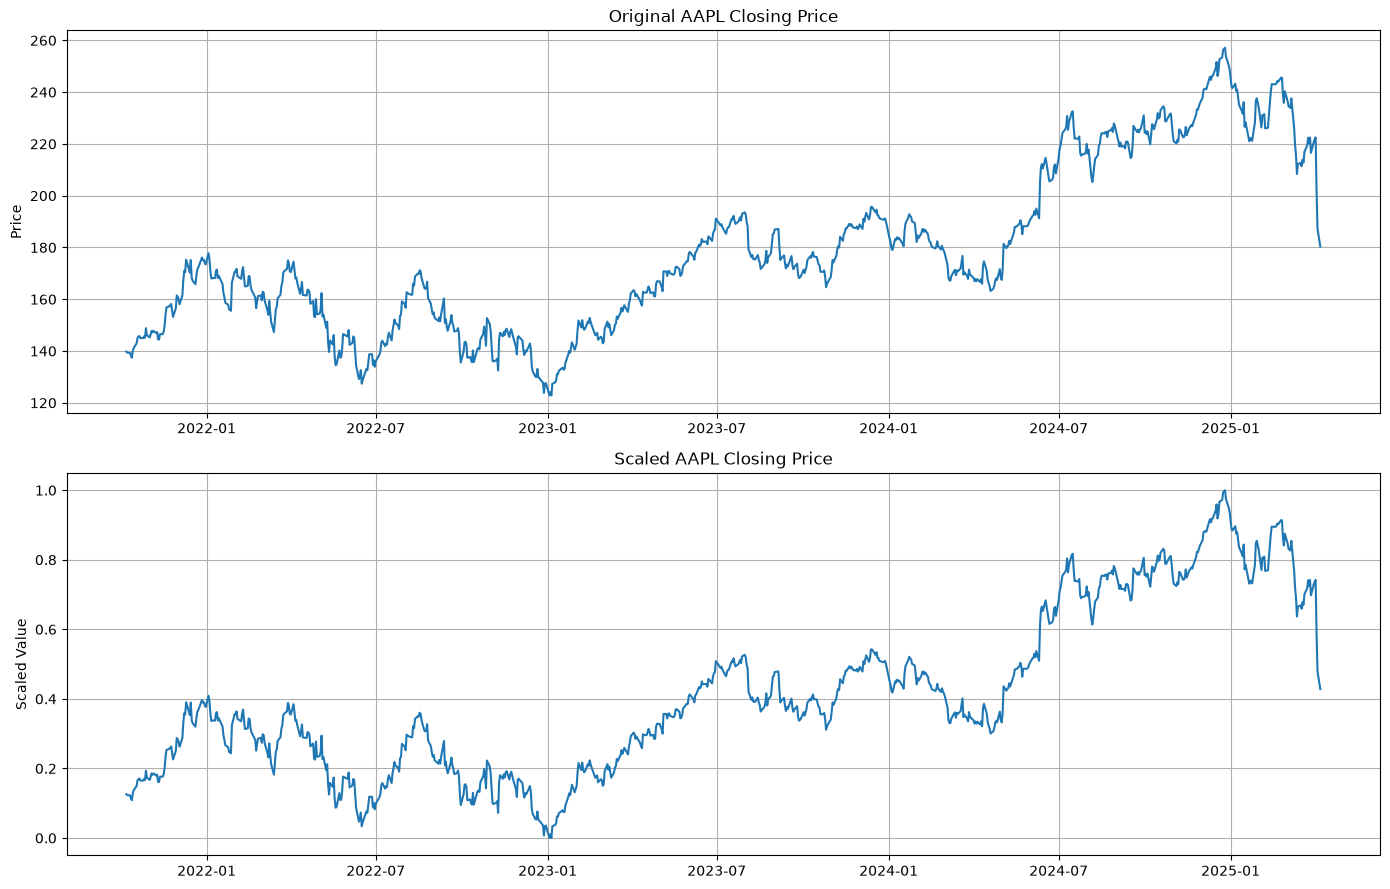

In [61]:
# ============================================================
# CELL 40 - ORIGINAL VS SCALED CLOSE PRICE
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9)
)

# Original price
axes[0].plot(
    apple_train.index,
    apple_train["Close"]
)

axes[0].set_title(
    "Original AAPL Closing Price"
)

axes[0].set_ylabel("Price")

axes[0].grid(True)


# Scaled price
axes[1].plot(
    apple_train_scaled.index,
    apple_train_scaled["Close"]
)

axes[1].set_title(
    "Scaled AAPL Closing Price"
)

axes[1].set_ylabel("Scaled Value")

axes[1].grid(True)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# CELL 41 - COMPLETE PREPROCESSING PIPELINE
# ============================================================

def preprocess_stock_data(data):
    """
    Complete preprocessing pipeline.

    Returns:
        X_train
        y_train
        X_validation
        y_validation
        X_test
        y_test
        scaler
    """

    # --------------------------------------------------------
    # 1. Split chronologically
    # --------------------------------------------------------

    train_data, validation_data, test_data = (
        split_time_series(data)
    )

    # --------------------------------------------------------
    # 2. Scale using training data only
    # --------------------------------------------------------

    (
        train_scaled,
        validation_scaled,
        test_scaled,
        scaler
    ) = scale_stock_data(
        train_data,
        validation_data,
        test_data
    )

    # --------------------------------------------------------
    # 3. Training sequences
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_scaled,
        SEQUENCE_LENGTH
    )

    # --------------------------------------------------------
    # 4. Validation sequences
    # --------------------------------------------------------

    X_validation, y_validation = (
        create_context_sequences(
            train_scaled.tail(SEQUENCE_LENGTH),
            validation_scaled,
            SEQUENCE_LENGTH
        )
    )

    # --------------------------------------------------------
    # 5. Test context
    # --------------------------------------------------------

    test_context = pd.concat(
        [
            train_scaled.tail(SEQUENCE_LENGTH),
            validation_scaled
        ]
    )

    # --------------------------------------------------------
    # 6. Test sequences
    # --------------------------------------------------------

    X_test, y_test = create_context_sequences(
        test_context,
        test_scaled,
        SEQUENCE_LENGTH
    )

    return (
        X_train,
        y_train,
        X_validation,
        y_validation,
        X_test,
        y_test,
        scaler
    )

In [63]:
# ============================================================
# CELL 42 - RUN COMPLETE PREPROCESSING PIPELINE
# ============================================================

(
    X_train,
    y_train,
    X_validation,
    y_validation,
    X_test,
    y_test,
    scaler
) = preprocess_stock_data(
    apple_data
)

print("\n" + "=" * 60)
print("PREPROCESSING COMPLETED")
print("=" * 60)

print("\nTraining:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Time-Series Split
Training   : 878 rows (70.0%)
Validation : 188 rows (15.0%)
Testing    : 189 rows (15.1%)

Date ranges:
Training   : 2021-10-07 → 2025-04-07
Validation : 2025-04-08 → 2026-01-06
Testing    : 2026-01-07 → 2026-10-07

PREPROCESSING COMPLETED

Training:
X_train: (818, 60, 5)
y_train: (818,)

Validation:
X_validation: (188, 60, 5)
y_validation: (188,)

Testing:
X_test: (189, 60, 5)
y_test: (189,)


In [64]:
# ============================================================
# CELL 43 - STEP 4 HEALTH CHECK
# ============================================================

print("=" * 60)
print("STEP 4 - DATA PREPROCESSING HEALTH CHECK")
print("=" * 60)

checks = {
    "Feature selection": True,
    "Chronological splitting": True,
    "Training-only scaler fitting": True,
    "MinMax scaling": True,
    "60-day sequence creation": True,
    "Validation context handling": True,
    "Test context handling": True,
    "LSTM input shape": X_train.ndim == 3,
    "Five input features": X_train.shape[2] == 5,
    "Scaler saving": os.path.exists("scalers/AAPL_scaler.pkl")
}

for check, status in checks.items():
    symbol = "✓" if status else "✗"
    print(f"{symbol} {check}")

print("\n" + "=" * 60)
print("STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 4 - DATA PREPROCESSING HEALTH CHECK
✓ Feature selection
✓ Chronological splitting
✓ Training-only scaler fitting
✓ MinMax scaling
✓ 60-day sequence creation
✓ Validation context handling
✓ Test context handling
✓ LSTM input shape
✓ Five input features
✓ Scaler saving

STEP 4 COMPLETED SUCCESSFULLY


**VANILLA LSTM BASELINE**

In [65]:
# ============================================================
# CELL 44 - LSTM MODEL IMPORTS
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("LSTM components loaded successfully.")

LSTM components loaded successfully.


In [66]:
# ============================================================
# CELL 45 - VANILLA LSTM CONFIGURATION
# ============================================================

LSTM_UNITS = PROJECT_CONFIG["lstm_units"]
DROPOUT_RATE = PROJECT_CONFIG["dropout"]
DENSE_UNITS = PROJECT_CONFIG["dense_units"]

EPOCHS = PROJECT_CONFIG["epochs"]
BATCH_SIZE = PROJECT_CONFIG["batch_size"]

print("Vanilla LSTM Configuration")
print("=" * 50)

print("LSTM Units       :", LSTM_UNITS)
print("Dropout          :", DROPOUT_RATE)
print("Dense Units      :", DENSE_UNITS)
print("Epochs           :", EPOCHS)
print("Batch Size       :", BATCH_SIZE)

Vanilla LSTM Configuration
LSTM Units       : 64
Dropout          : 0.2
Dense Units      : 32
Epochs           : 30
Batch Size       : 64


In [67]:
# ============================================================
# CELL 46 - BUILD VANILLA LSTM MODEL
# ============================================================

def build_vanilla_lstm(
    sequence_length=SEQUENCE_LENGTH,
    number_of_features=len(FEATURE_COLUMNS)
):
    """
    Build a simple Vanilla LSTM model.

    Input:
        60 trading days × 5 OHLCV features

    Output:
        Next trading day's closing price
    """

    model = Sequential()

    # LSTM layer
    model.add(
        LSTM(
            LSTM_UNITS,
            input_shape=(
                sequence_length,
                number_of_features
            )
        )
    )

    # Dropout to reduce overfitting
    model.add(
        Dropout(DROPOUT_RATE)
    )

    # Dense hidden layer
    model.add(
        Dense(DENSE_UNITS, activation="relu")
    )

    # Final prediction
    model.add(
        Dense(1)
    )

    # Compile model
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mae"]
    )

    return model


vanilla_lstm = build_vanilla_lstm()

print("Vanilla LSTM model created successfully.")

Vanilla LSTM model created successfully.


In [68]:
# ============================================================
# CELL 47 - DISPLAY MODEL ARCHITECTURE
# ============================================================

vanilla_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

In [69]:
# ============================================================
# CELL 48 - EARLY STOPPING
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=PROJECT_CONFIG["early_stopping_patience"],
    restore_best_weights=True
)

print("Early stopping configured.")
print(
    "Patience:",
    PROJECT_CONFIG["early_stopping_patience"]
)

Early stopping configured.
Patience: 5


In [70]:
# ============================================================
# CELL 49 - TRAIN VANILLA LSTM
# ============================================================

print("Starting Vanilla LSTM training...")
print("=" * 60)

vanilla_history = vanilla_lstm.fit(
    X_train,
    y_train,

    validation_data=(
        X_validation,
        y_validation
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    callbacks=[
        early_stopping
    ],

    shuffle=False,

    verbose=1
)

print("\nVanilla LSTM training completed.")

Starting Vanilla LSTM training...
Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 268ms/step - loss: 0.0217 - mae: 0.1181 - val_loss: 0.0101 - val_mae: 0.0831
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0250 - mae: 0.1302 - val_loss: 0.0266 - val_mae: 0.1355
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0118 - mae: 0.0924 - val_loss: 0.0124 - val_mae: 0.0910
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0109 - mae: 0.0788 - val_loss: 0.0131 - val_mae: 0.0960
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0068 - mae: 0.0661 - val_loss: 0.0044 - val_mae: 0.0533
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0077 - mae: 0.0661 - val_loss: 0.0058 - val_mae: 0.0626
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0058 - mae: 0.0596 - val_loss: 0.0039 - val_mae: 0.0502
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0066 - mae: 0.0627 - val_loss: 0.0068 - val_mae: 0.0692
Epoch 9/30
13/13 ━━━━━━━━━━━━

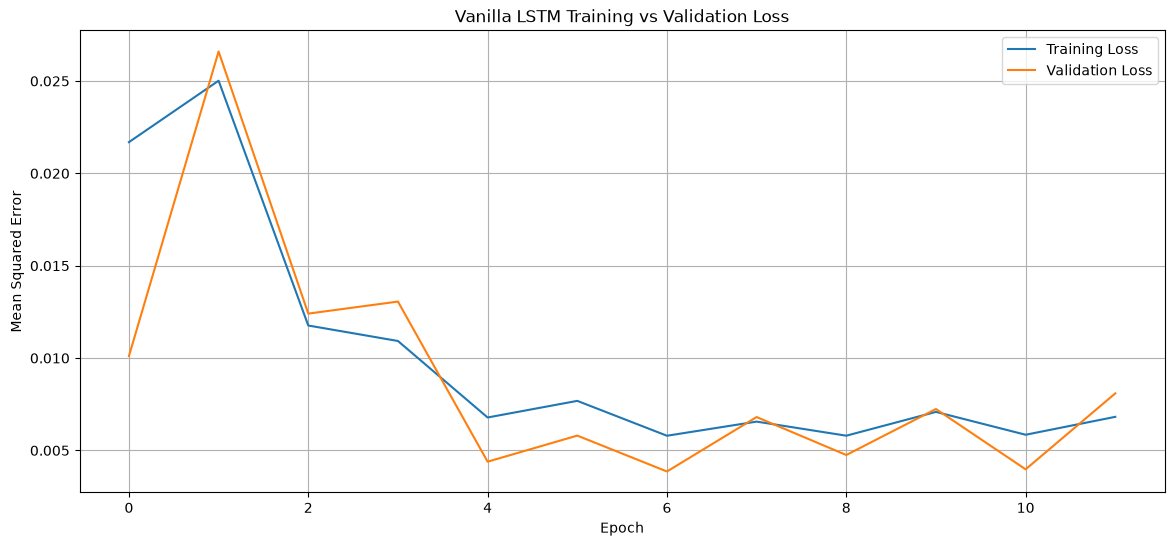

In [71]:
# ============================================================
# CELL 50 - TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    vanilla_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    vanilla_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Vanilla LSTM Training vs Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)

plt.show()

In [72]:
# ============================================================
# CELL 51 - GENERATE TEST PREDICTIONS
# ============================================================

y_pred_scaled = vanilla_lstm.predict(
    X_test,
    verbose=0
)

print("Prediction completed.")

print("Prediction shape:")
print(y_pred_scaled.shape)

Prediction completed.
Prediction shape:
(189, 1)


In [73]:
# ============================================================
# CELL 52 - INVERSE TRANSFORM CLOSE PRICE
# ============================================================

def inverse_transform_close(
    scaled_close_values,
    scaler
):
    """
    Convert scaled Close predictions back
    to the original price scale.
    """

    scaled_close_values = np.asarray(
        scaled_close_values
    ).reshape(-1)

    # Create empty array for all five features
    dummy_array = np.zeros(
        (
            len(scaled_close_values),
            len(FEATURE_COLUMNS)
        )
    )

    # Put predicted Close into the correct column
    close_index = FEATURE_COLUMNS.index(
        TARGET_COLUMN
    )

    dummy_array[:, close_index] = (
        scaled_close_values
    )

    # Inverse transform
    original_scale = scaler.inverse_transform(
        dummy_array
    )

    # Return only Close
    return original_scale[
        :,
        close_index
    ]

In [74]:
# ============================================================
# CELL 53 - CONVERT PREDICTIONS TO REAL PRICES
# ============================================================

actual_prices = inverse_transform_close(
    y_test,
    scaler
)

predicted_prices = inverse_transform_close(
    y_pred_scaled,
    scaler
)

print("Actual prices shape   :", actual_prices.shape)
print("Predicted prices shape:", predicted_prices.shape)

print("\nFirst 5 predictions:")
print(predicted_prices[:5])

Actual prices shape   : (189,)
Predicted prices shape: (189,)

First 5 predictions:
[261.62424991 260.22843497 258.52461134 257.17516984 256.2580694 ]


In [75]:
# ============================================================
# CELL 54 - MODEL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    actual_prices,
    predicted_prices
)

rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        predicted_prices
    )
)

mape = np.mean(
    np.abs(
        (actual_prices - predicted_prices)
        / actual_prices
    )
) * 100

print("=" * 50)
print("VANILLA LSTM PERFORMANCE")
print("=" * 50)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")

VANILLA LSTM PERFORMANCE
MAE  : 16.9822
RMSE : 20.5372
MAPE : 5.54%


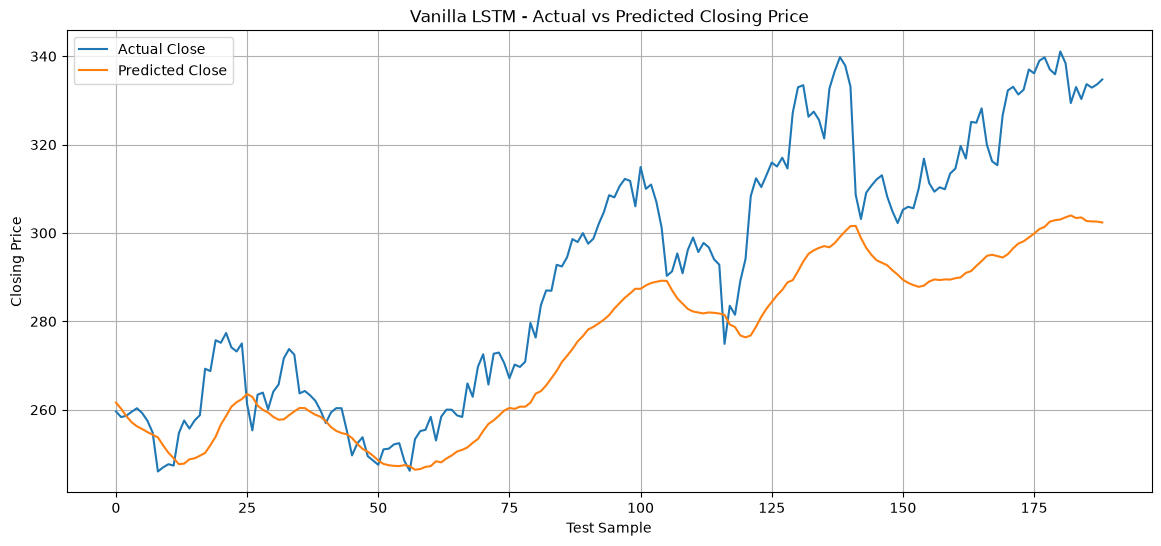

In [76]:
# ============================================================
# CELL 55 - ACTUAL VS PREDICTED PRICE
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    actual_prices,
    label="Actual Close"
)

plt.plot(
    predicted_prices,
    label="Predicted Close"
)

plt.title(
    "Vanilla LSTM - Actual vs Predicted Closing Price"
)

plt.xlabel("Test Sample")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.show()

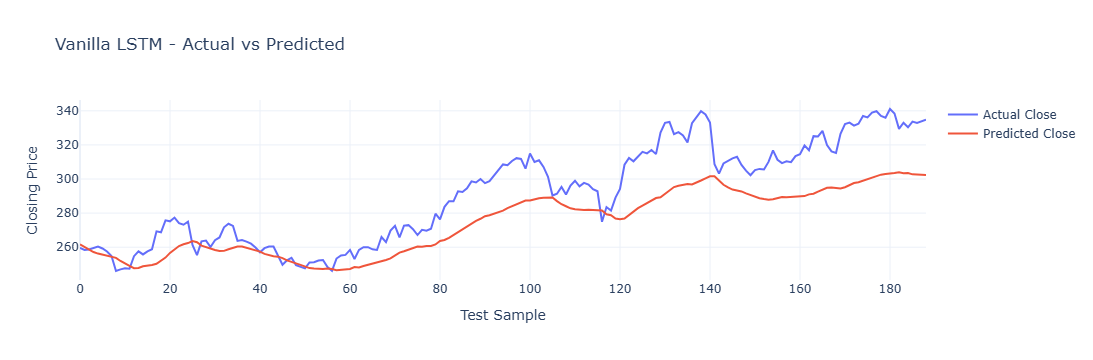

In [77]:
# ============================================================
# CELL 56 - INTERACTIVE PREDICTION GRAPH
# ============================================================

prediction_df = pd.DataFrame({
    "Actual": actual_prices,
    "Predicted": predicted_prices
})

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        y=prediction_df["Actual"],
        mode="lines",
        name="Actual Close"
    )
)

fig.add_trace(
    go.Scatter(
        y=prediction_df["Predicted"],
        mode="lines",
        name="Predicted Close"
    )
)

fig.update_layout(
    title="Vanilla LSTM - Actual vs Predicted",
    xaxis_title="Test Sample",
    yaxis_title="Closing Price",
    hovermode="x unified",
    template="plotly_white"
)

fig.show()

In [78]:
# ============================================================
# CELL 57 - SAVE VANILLA LSTM MODEL
# ============================================================

vanilla_model_path = os.path.join(
    "models",
    "AAPL_vanilla_lstm.keras"
)

vanilla_lstm.save(
    vanilla_model_path
)

print("Vanilla LSTM model saved successfully:")
print(vanilla_model_path)

Vanilla LSTM model saved successfully:
models\AAPL_vanilla_lstm.keras


In [79]:
# ============================================================
# CELL 58 - SAVE VANILLA LSTM RESULTS
# ============================================================

vanilla_results = {
    "ticker": "AAPL",
    "model": "Vanilla LSTM",
    "MAE": float(mae),
    "RMSE": float(rmse),
    "MAPE": float(mape),
    "sequence_length": SEQUENCE_LENGTH,
    "features": FEATURE_COLUMNS,
    "epochs": len(
        vanilla_history.history["loss"]
    ),
    "created_on": datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )
}

vanilla_results_path = os.path.join(
    "results",
    "AAPL_vanilla_lstm_results.json"
)

with open(
    vanilla_results_path,
    "w"
) as file:

    json.dump(
        vanilla_results,
        file,
        indent=4
    )

print("Baseline results saved:")
print(vanilla_results_path)

Baseline results saved:
results\AAPL_vanilla_lstm_results.json


In [80]:
# ============================================================
# CELL 59 - STEP 5 HEALTH CHECK
# ============================================================

print("=" * 60)
print("STEP 5 - VANILLA LSTM HEALTH CHECK")
print("=" * 60)

checks = {
    "Model created": vanilla_lstm is not None,
    "Training completed": len(
        vanilla_history.history["loss"]
    ) > 0,
    "Predictions generated": len(
        predicted_prices
    ) > 0,
    "MAE calculated": np.isfinite(mae),
    "RMSE calculated": np.isfinite(rmse),
    "MAPE calculated": np.isfinite(mape),
    "Model saved": os.path.exists(
        vanilla_model_path
    ),
    "Results saved": os.path.exists(
        vanilla_results_path
    )
}

for check, status in checks.items():

    symbol = "✓" if status else "✗"

    print(
        f"{symbol} {check}"
    )

print("\n" + "=" * 60)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 5 - VANILLA LSTM HEALTH CHECK
✓ Model created
✓ Training completed
✓ Predictions generated
✓ MAE calculated
✓ RMSE calculated
✓ MAPE calculated
✓ Model saved
✓ Results saved

STEP 5 COMPLETED SUCCESSFULLY


**LSTM + Temporal Attention**

In [81]:
# ============================================================
# CELL 60 - TEMPORAL ATTENTION LAYER
# ============================================================

class TemporalAttention(Layer):
    """
    Temporal Attention mechanism.

    The layer assigns a learnable importance weight
    to each time step in the LSTM output.
    """

    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):

        # Learnable attention weights
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        # Learnable attention bias
        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):

        # Calculate attention scores
        score = tf.nn.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        # Convert scores into attention weights
        attention_weights = tf.nn.softmax(
            score,
            axis=1
        )

        # Weighted sum of LSTM outputs
        context_vector = (
            inputs * attention_weights
        )

        context_vector = tf.reduce_sum(
            context_vector,
            axis=1
        )

        return context_vector


print("Temporal Attention layer created successfully.")

Temporal Attention layer created successfully.


In [82]:
# ============================================================
# CELL 61 - BUILD LSTM + ATTENTION MODEL
# ============================================================

def build_lstm_attention_model(
    sequence_length=SEQUENCE_LENGTH,
    number_of_features=len(FEATURE_COLUMNS)
):
    """
    Build LSTM with Temporal Attention.

    Input:
        60 trading days × 5 OHLCV features

    Output:
        Next trading day's closing price
    """

    inputs = Input(
        shape=(
            sequence_length,
            number_of_features
        )
    )

    # LSTM must return all time steps
    # because attention needs every time step.
    lstm_output = LSTM(
        LSTM_UNITS,
        return_sequences=True
    )(inputs)

    # Temporal attention
    attention_output = TemporalAttention()(
        lstm_output
    )

    # Dropout
    dropout_output = Dropout(
        DROPOUT_RATE
    )(attention_output)

    # Dense layer
    dense_output = Dense(
        DENSE_UNITS,
        activation="relu"
    )(dropout_output)

    # Final prediction
    output = Dense(
        1
    )(dense_output)

    model = Model(
        inputs=inputs,
        outputs=output
    )

    # Compile
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mae"]
    )

    return model


attention_model = build_lstm_attention_model()

print("LSTM + Attention model created successfully.")


LSTM + Attention model created successfully.


In [83]:
# ============================================================
# CELL 62 - DISPLAY LSTM + ATTENTION ARCHITECTURE
# ============================================================

attention_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 64)             │           124 │
│ (TemporalAttention)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,157 (78.74 KB)

 Trainable params: 20,157 (78.74 KB)

 Non-trainable params: 0 (0.00 B)

In [84]:
# ============================================================
# CELL 63 - ATTENTION MODEL EARLY STOPPING
# ============================================================

attention_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=PROJECT_CONFIG["early_stopping_patience"],
    restore_best_weights=True
)

print("Attention model early stopping configured.")

Attention model early stopping configured.


In [85]:
# ============================================================
# CELL 64 - TRAIN LSTM + ATTENTION
# ============================================================

print("Starting LSTM + Attention training...")
print("=" * 60)

attention_history = attention_model.fit(
    X_train,
    y_train,

    validation_data=(
        X_validation,
        y_validation
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    callbacks=[
        attention_early_stopping
    ],

    shuffle=False,

    verbose=1
)

print("\nLSTM + Attention training completed.")

Starting LSTM + Attention training...
Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 285ms/step - loss: 0.0408 - mae: 0.1707 - val_loss: 0.0323 - val_mae: 0.1345
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0284 - mae: 0.1346 - val_loss: 0.0543 - val_mae: 0.1941
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0134 - mae: 0.0918 - val_loss: 0.0239 - val_mae: 0.1349
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0142 - mae: 0.0968 - val_loss: 0.0268 - val_mae: 0.1414
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0123 - mae: 0.0897 - val_loss: 0.0213 - val_mae: 0.1267
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0133 - mae: 0.0928 - val_loss: 0.0206 - val_mae: 0.1242
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0114 - mae: 0.0874 - val_loss: 0.0201 - val_mae: 0.1223
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0130 - mae: 0.0920 - val_loss: 0.0222 - val_mae: 0.1283
Epoch 9/30
13/13 ━━━━━━━━

In [86]:
shuffle=False

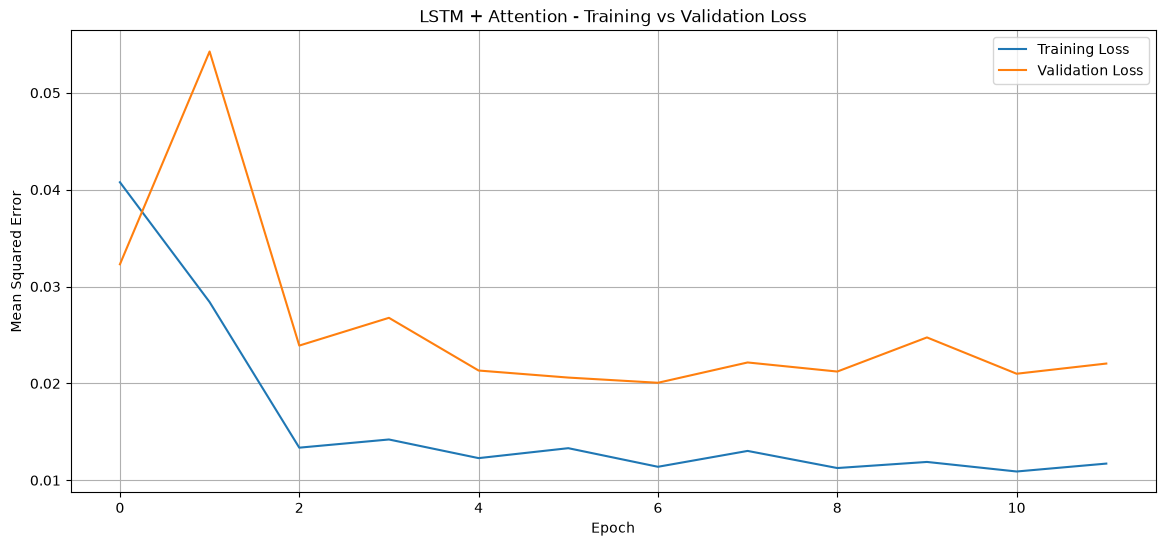

In [87]:
# ============================================================
# CELL 65 - ATTENTION TRAINING HISTORY
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    attention_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    attention_history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "LSTM + Attention - Training vs Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)

plt.show()

In [88]:
# ============================================================
# CELL 66 - GENERATE ATTENTION PREDICTIONS
# ============================================================

attention_pred_scaled = attention_model.predict(
    X_test,
    verbose=0
)

print("Attention predictions generated.")

print(
    "Prediction shape:",
    attention_pred_scaled.shape
)

Attention predictions generated.
Prediction shape: (189, 1)


In [89]:
# ============================================================
# CELL 67 - CONVERT ATTENTION PREDICTIONS
# ============================================================

attention_predicted_prices = (
    inverse_transform_close(
        attention_pred_scaled,
        scaler
    )
)

print("Attention predictions converted to real prices.")

print("\nFirst 5 predictions:")

print(
    attention_predicted_prices[:5]
)

Attention predictions converted to real prices.

First 5 predictions:
[263.6460903  263.90617228 264.14960082 264.38848168 264.57724208]


In [90]:
# ============================================================
# CELL 68 - ATTENTION MODEL EVALUATION
# ============================================================

attention_mae = mean_absolute_error(
    actual_prices,
    attention_predicted_prices
)

attention_rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        attention_predicted_prices
    )
)

attention_mape = np.mean(
    np.abs(
        (
            actual_prices -
            attention_predicted_prices
        )
        / actual_prices
    )
) * 100

print("=" * 50)
print("LSTM + ATTENTION PERFORMANCE")
print("=" * 50)

print(
    f"MAE  : {attention_mae:.4f}"
)

print(
    f"RMSE : {attention_rmse:.4f}"
)

print(
    f"MAPE : {attention_mape:.2f}%"
)

LSTM + ATTENTION PERFORMANCE
MAE  : 21.9954
RMSE : 26.9190
MAPE : 7.18%


In [91]:
# ============================================================
# CELL 69 - COMPARE VANILLA LSTM VS ATTENTION
# ============================================================

comparison_df = pd.DataFrame({

    "Model": [
        "Vanilla LSTM",
        "LSTM + Attention"
    ],

    "MAE": [
        mae,
        attention_mae
    ],

    "RMSE": [
        rmse,
        attention_rmse
    ],

    "MAPE (%)": [
        mape,
        attention_mape
    ]
})

display(comparison_df)

,Model,MAE,RMSE,MAPE (%)
0,Vanilla LSTM,16.982249,20.537192,5.540351
1,LSTM + Attention,21.995426,26.918973,7.179785


In [92]:
# ============================================================
# CELL 70 - ATTENTION IMPROVEMENT
# ============================================================

mae_improvement = (
    (mae - attention_mae)
    / mae
) * 100

rmse_improvement = (
    (rmse - attention_rmse)
    / rmse
) * 100

mape_improvement = (
    (mape - attention_mape)
    / mape
) * 100

print("=" * 60)
print("ATTENTION MODEL IMPROVEMENT")
print("=" * 60)

print(
    f"MAE improvement  : {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement : {rmse_improvement:.2f}%"
)

print(
    f"MAPE improvement : {mape_improvement:.2f}%"
)

ATTENTION MODEL IMPROVEMENT
MAE improvement  : -29.52%
RMSE improvement : -31.07%
MAPE improvement : -29.59%


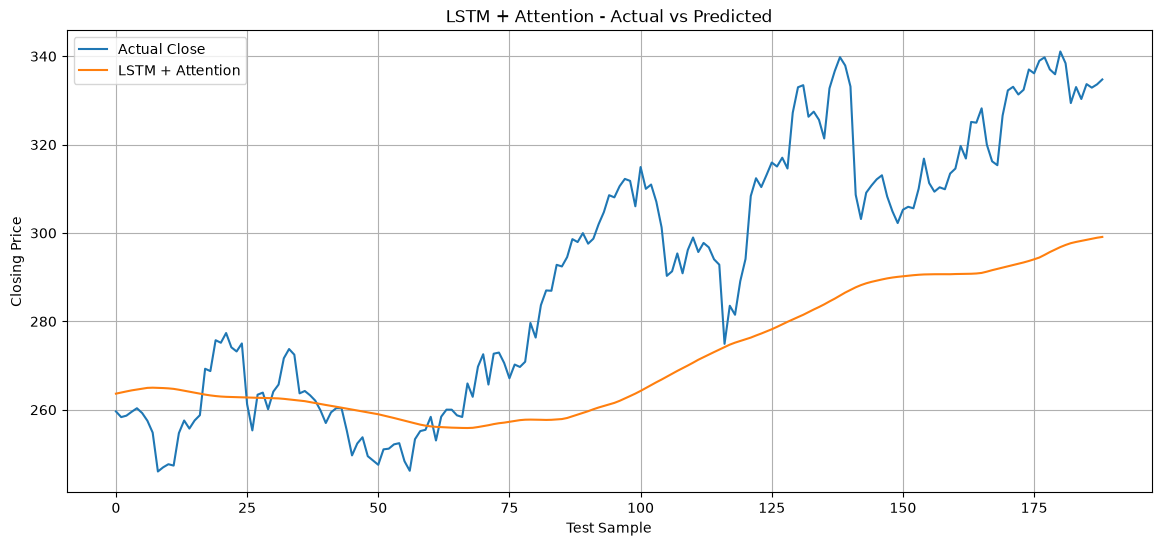

In [93]:
# ============================================================
# CELL 71 - ACTUAL VS ATTENTION PREDICTION
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    actual_prices,
    label="Actual Close"
)

plt.plot(
    attention_predicted_prices,
    label="LSTM + Attention"
)

plt.title(
    "LSTM + Attention - Actual vs Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.show()

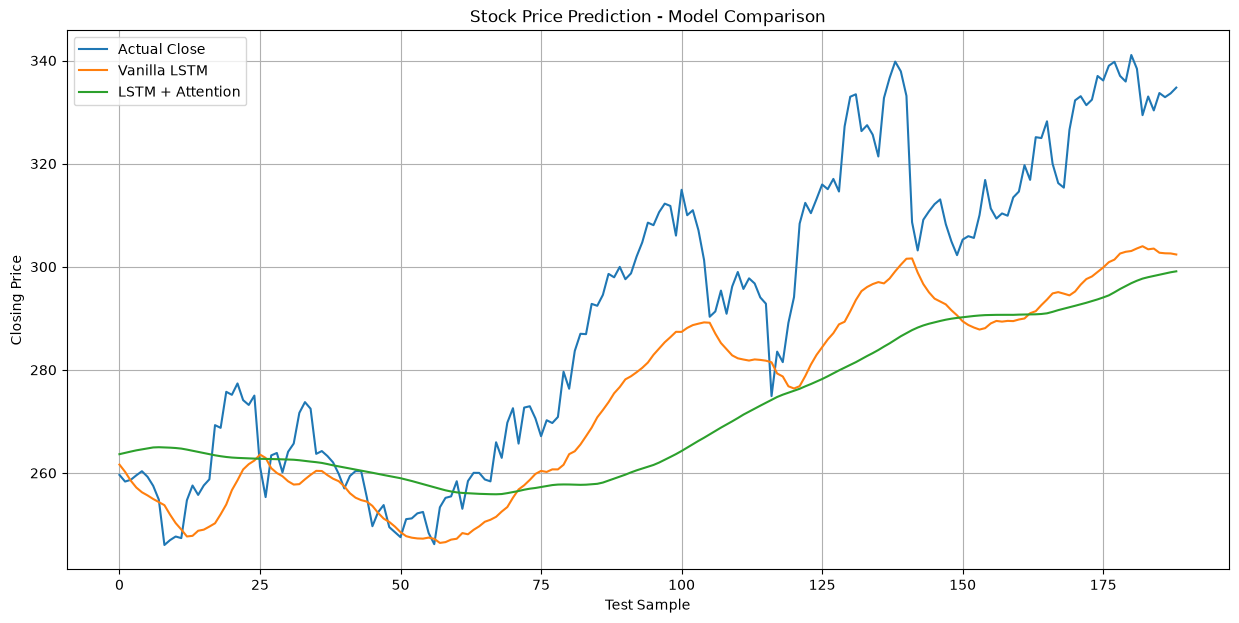

In [94]:
# ============================================================
# CELL 72 - COMPLETE MODEL COMPARISON
# ============================================================

plt.figure(figsize=(15, 7))

plt.plot(
    actual_prices,
    label="Actual Close"
)

plt.plot(
    predicted_prices,
    label="Vanilla LSTM"
)

plt.plot(
    attention_predicted_prices,
    label="LSTM + Attention"
)

plt.title(
    "Stock Price Prediction - Model Comparison"
)

plt.xlabel("Test Sample")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.show()

In [99]:
# ============================================================
# CELL 73 - SAVE LSTM + ATTENTION MODEL
# ============================================================

attention_model_path = os.path.join(
    "models",
    "AAPL_lstm_attention.keras"
)

attention_model.save(
    attention_model_path
)

print("LSTM + Attention model saved successfully:")

print(
    attention_model_path
)

LSTM + Attention model saved successfully:
models\AAPL_lstm_attention.keras


In [100]:
# ============================================================
# CELL 74 - SAVE ATTENTION RESULTS
# ============================================================

attention_results = {

    "ticker": "AAPL",

    "model": "LSTM with Temporal Attention",

    "MAE": float(attention_mae),

    "RMSE": float(attention_rmse),

    "MAPE": float(attention_mape),

    "sequence_length": SEQUENCE_LENGTH,

    "features": FEATURE_COLUMNS,

    "epochs": len(
        attention_history.history["loss"]
    ),

    "created_on": datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )
}

attention_results_path = os.path.join(
    "results",
    "AAPL_lstm_attention_results.json"
)

with open(
    attention_results_path,
    "w"
) as file:

    json.dump(
        attention_results,
        file,
        indent=4
    )

print("Attention results saved:")
print(attention_results_path)

Attention results saved:
results\AAPL_lstm_attention_results.json


In [101]:
# ============================================================
# CELL 75 - STEP 6 HEALTH CHECK
# ============================================================

print("=" * 60)
print("STEP 6 - LSTM + ATTENTION HEALTH CHECK")
print("=" * 60)

checks = {

    "Attention layer created":
        attention_model is not None,

    "Training completed":
        len(
            attention_history.history["loss"]
        ) > 0,

    "Predictions generated":
        len(
            attention_predicted_prices
        ) > 0,

    "MAE calculated":
        np.isfinite(attention_mae),

    "RMSE calculated":
        np.isfinite(attention_rmse),

    "MAPE calculated":
        np.isfinite(attention_mape),

    "Attention model saved":
        os.path.exists(
            attention_model_path
        ),

    "Results saved":
        os.path.exists(
            attention_results_path
        )
}

for check, status in checks.items():

    symbol = "✓" if status else "✗"

    print(
        f"{symbol} {check}"
    )

print("\n" + "=" * 60)
print("STEP 6 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 6 - LSTM + ATTENTION HEALTH CHECK
✓ Attention layer created
✓ Training completed
✓ Predictions generated
✓ MAE calculated
✓ RMSE calculated
✓ MAPE calculated
✓ Attention model saved
✓ Results saved

STEP 6 COMPLETED SUCCESSFULLY


In [102]:
# ============================================================
# CELL 76 - CREATE EVALUATION DATAFRAME
# ============================================================

evaluation_df = pd.DataFrame({
    "Actual": actual_prices,
    "Vanilla_LSTM": predicted_prices,
    "LSTM_Attention": attention_predicted_prices
})

# Calculate prediction errors
evaluation_df["Vanilla_Error"] = (
    evaluation_df["Actual"]
    - evaluation_df["Vanilla_LSTM"]
)

evaluation_df["Attention_Error"] = (
    evaluation_df["Actual"]
    - evaluation_df["LSTM_Attention"]
)

print("Evaluation dataframe created successfully.")

display(evaluation_df.head())

Evaluation dataframe created successfully.


,Actual,Vanilla_LSTM,LSTM_Attention,Vanilla_Error,Attention_Error
0,259.623291,261.624250,263.646090,-2.000959,-4.022799
1,258.336853,260.228435,263.906172,-1.891582,-5.569319
2,258.665924,258.524611,264.149601,0.141313,-5.483677
3,259.543518,257.175170,264.388482,2.368348,-4.844964
4,260.341339,256.258069,264.577242,4.083270,-4.235903


In [103]:
# ============================================================
# CELL 77 - DETAILED MODEL METRICS
# ============================================================

metrics_df = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "MAPE (%)"
    ],

    "Vanilla LSTM": [
        mae,
        rmse,
        mape
    ],

    "LSTM + Attention": [
        attention_mae,
        attention_rmse,
        attention_mape
    ]
})

display(
    metrics_df.style.format({
        "Vanilla LSTM": "{:.4f}",
        "LSTM + Attention": "{:.4f}"
    })
)

,Metric,Vanilla LSTM,LSTM + Attention
0,MAE,16.9822,21.9954
1,RMSE,20.5372,26.9190
2,MAPE (%),5.5404,7.1798


In [104]:
# ============================================================
# CELL 78 - DETERMINE BEST MODEL
# ============================================================

model_scores = {
    "Vanilla LSTM": {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    },

    "LSTM + Attention": {
        "MAE": attention_mae,
        "RMSE": attention_rmse,
        "MAPE": attention_mape
    }
}

best_mae_model = min(
    model_scores,
    key=lambda model: model_scores[model]["MAE"]
)

best_rmse_model = min(
    model_scores,
    key=lambda model: model_scores[model]["RMSE"]
)

best_mape_model = min(
    model_scores,
    key=lambda model: model_scores[model]["MAPE"]
)

print("Best Model by Metric")
print("=" * 50)

print("Lowest MAE  :", best_mae_model)
print("Lowest RMSE :", best_rmse_model)
print("Lowest MAPE :", best_mape_model)

Best Model by Metric
Lowest MAE  : Vanilla LSTM
Lowest RMSE : Vanilla LSTM
Lowest MAPE : Vanilla LSTM


In [105]:
# ============================================================
# CELL 79 - METRIC IMPROVEMENT
# ============================================================

improvement_df = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "MAPE (%)"
    ],

    "Vanilla LSTM": [
        mae,
        rmse,
        mape
    ],

    "LSTM + Attention": [
        attention_mae,
        attention_rmse,
        attention_mape
    ],

    "Improvement (%)": [
        ((mae - attention_mae) / mae) * 100,

        ((rmse - attention_rmse) / rmse) * 100,

        ((mape - attention_mape) / mape) * 100
    ]
})

display(
    improvement_df.style.format({
        "Vanilla LSTM": "{:.4f}",
        "LSTM + Attention": "{:.4f}",
        "Improvement (%)": "{:.2f}%"
    })
)

,Metric,Vanilla LSTM,LSTM + Attention,Improvement (%)
0,MAE,16.9822,21.9954,-29.52%
1,RMSE,20.5372,26.9190,-31.07%
2,MAPE (%),5.5404,7.1798,-29.59%


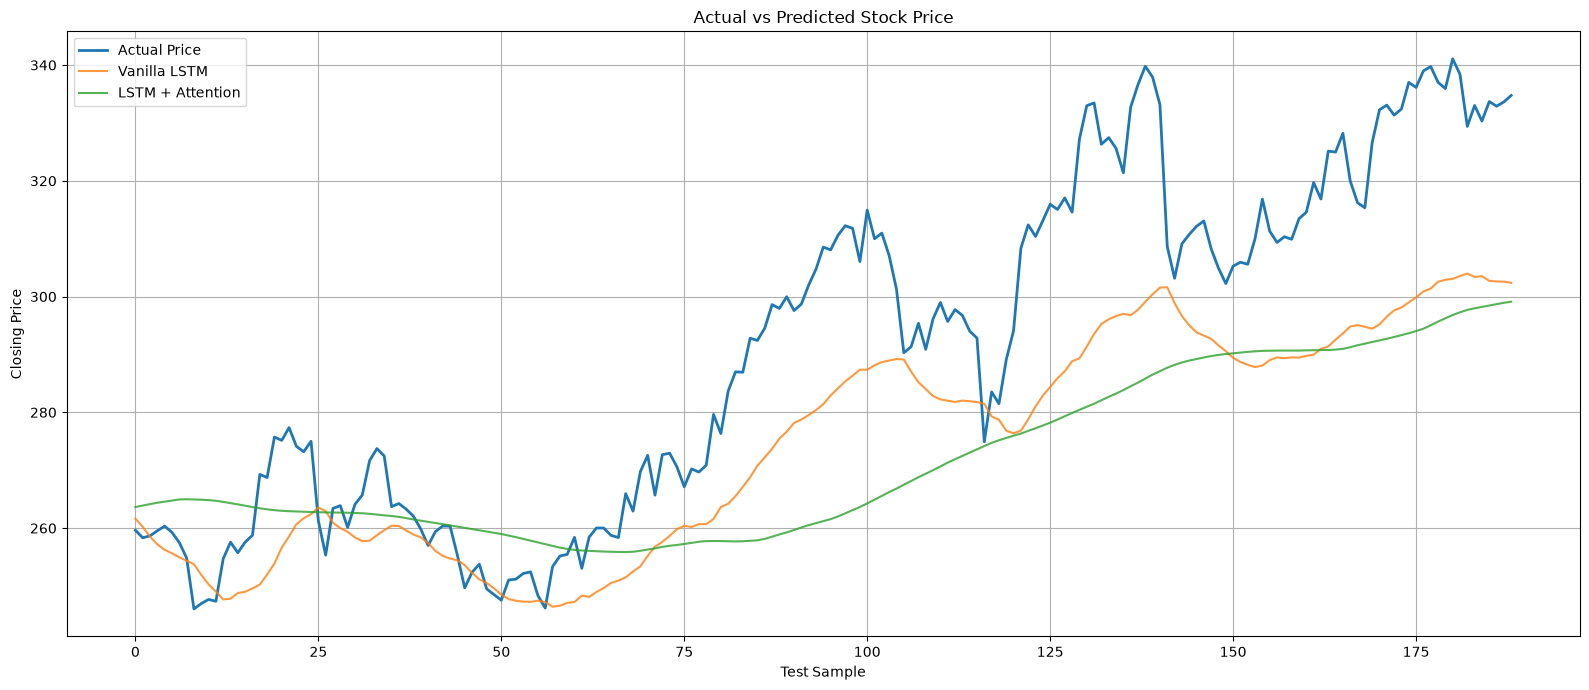

In [106]:
# ============================================================
# CELL 80 - ACTUAL VS BOTH MODELS
# ============================================================

plt.figure(figsize=(16, 7))

plt.plot(
    evaluation_df["Actual"],
    label="Actual Price",
    linewidth=2
)

plt.plot(
    evaluation_df["Vanilla_LSTM"],
    label="Vanilla LSTM",
    alpha=0.8
)

plt.plot(
    evaluation_df["LSTM_Attention"],
    label="LSTM + Attention",
    alpha=0.8
)

plt.title(
    "Actual vs Predicted Stock Price"
)

plt.xlabel("Test Sample")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

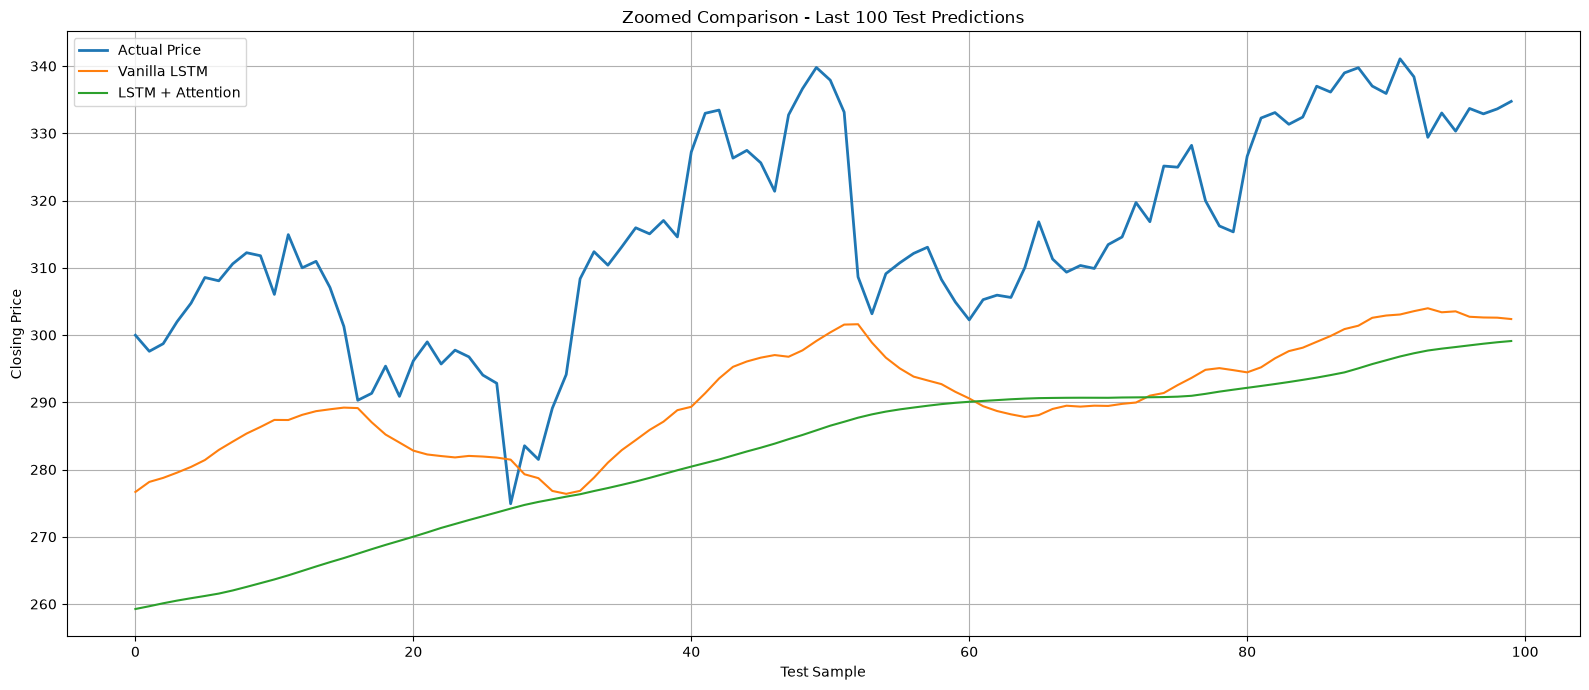

In [107]:
# ============================================================
# CELL 81 - ZOOMED PREDICTION COMPARISON
# ============================================================

zoom_data = evaluation_df.tail(100)

plt.figure(figsize=(16, 7))

plt.plot(
    zoom_data["Actual"].values,
    label="Actual Price",
    linewidth=2
)

plt.plot(
    zoom_data["Vanilla_LSTM"].values,
    label="Vanilla LSTM"
)

plt.plot(
    zoom_data["LSTM_Attention"].values,
    label="LSTM + Attention"
)

plt.title(
    "Zoomed Comparison - Last 100 Test Predictions"
)

plt.xlabel("Test Sample")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

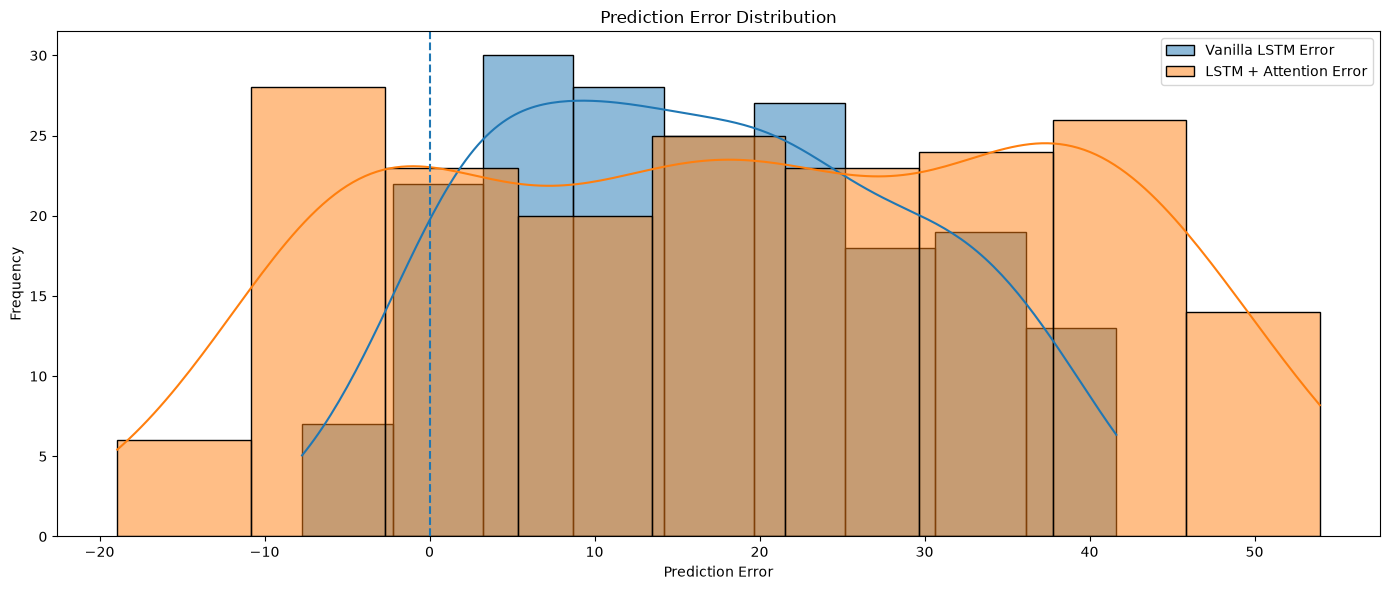

In [108]:
# ============================================================
# CELL 82 - ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(14, 6))

sns.histplot(
    evaluation_df["Vanilla_Error"],
    kde=True,
    label="Vanilla LSTM Error",
    alpha=0.5
)

sns.histplot(
    evaluation_df["Attention_Error"],
    kde=True,
    label="LSTM + Attention Error",
    alpha=0.5
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Prediction Error Distribution"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.legend()

plt.tight_layout()
plt.show()

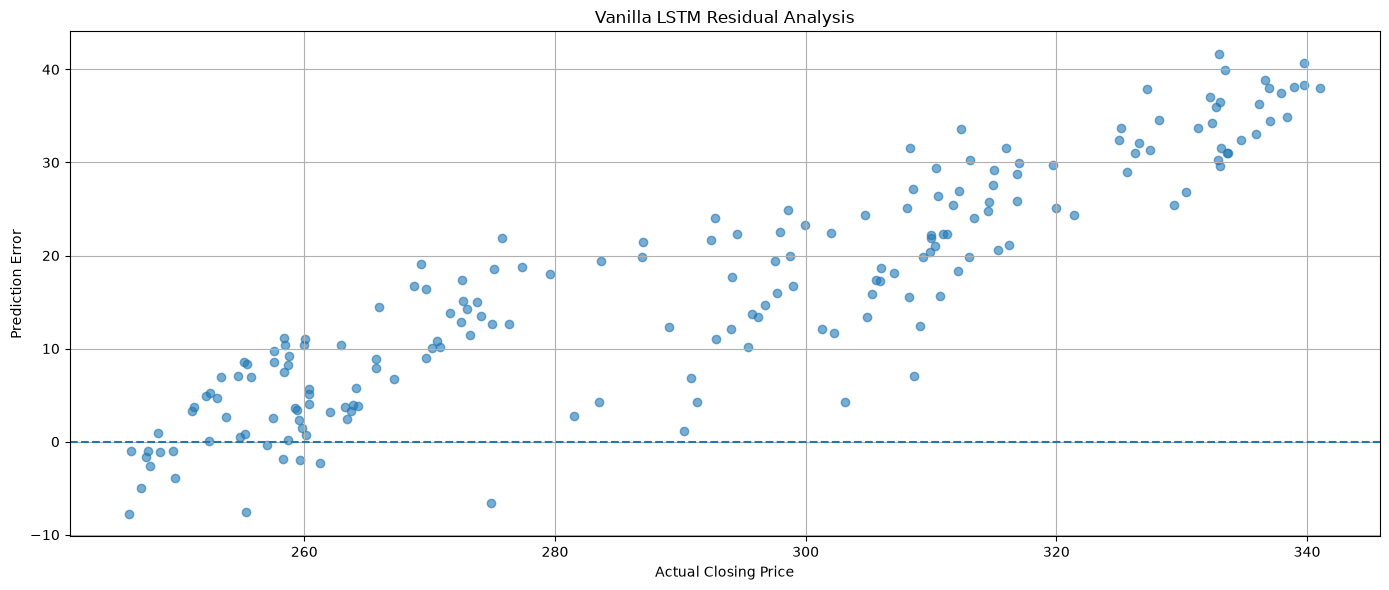

In [109]:
# ============================================================
# CELL 83 - VANILLA LSTM RESIDUAL ANALYSIS
# ============================================================

plt.figure(figsize=(14, 6))

plt.scatter(
    evaluation_df["Actual"],
    evaluation_df["Vanilla_Error"],
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Vanilla LSTM Residual Analysis"
)

plt.xlabel("Actual Closing Price")
plt.ylabel("Prediction Error")

plt.grid(True)

plt.tight_layout()
plt.show()

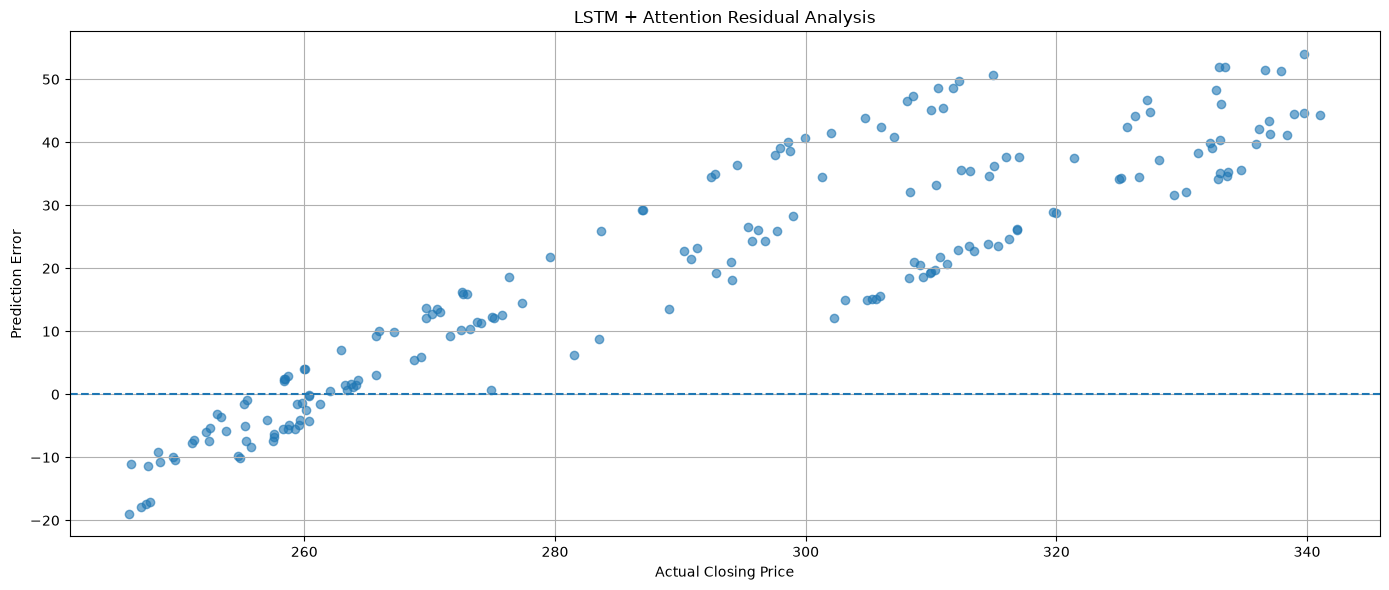

In [110]:
# ============================================================
# CELL 84 - ATTENTION MODEL RESIDUAL ANALYSIS
# ============================================================

plt.figure(figsize=(14, 6))

plt.scatter(
    evaluation_df["Actual"],
    evaluation_df["Attention_Error"],
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "LSTM + Attention Residual Analysis"
)

plt.xlabel("Actual Closing Price")
plt.ylabel("Prediction Error")

plt.grid(True)

plt.tight_layout()
plt.show()

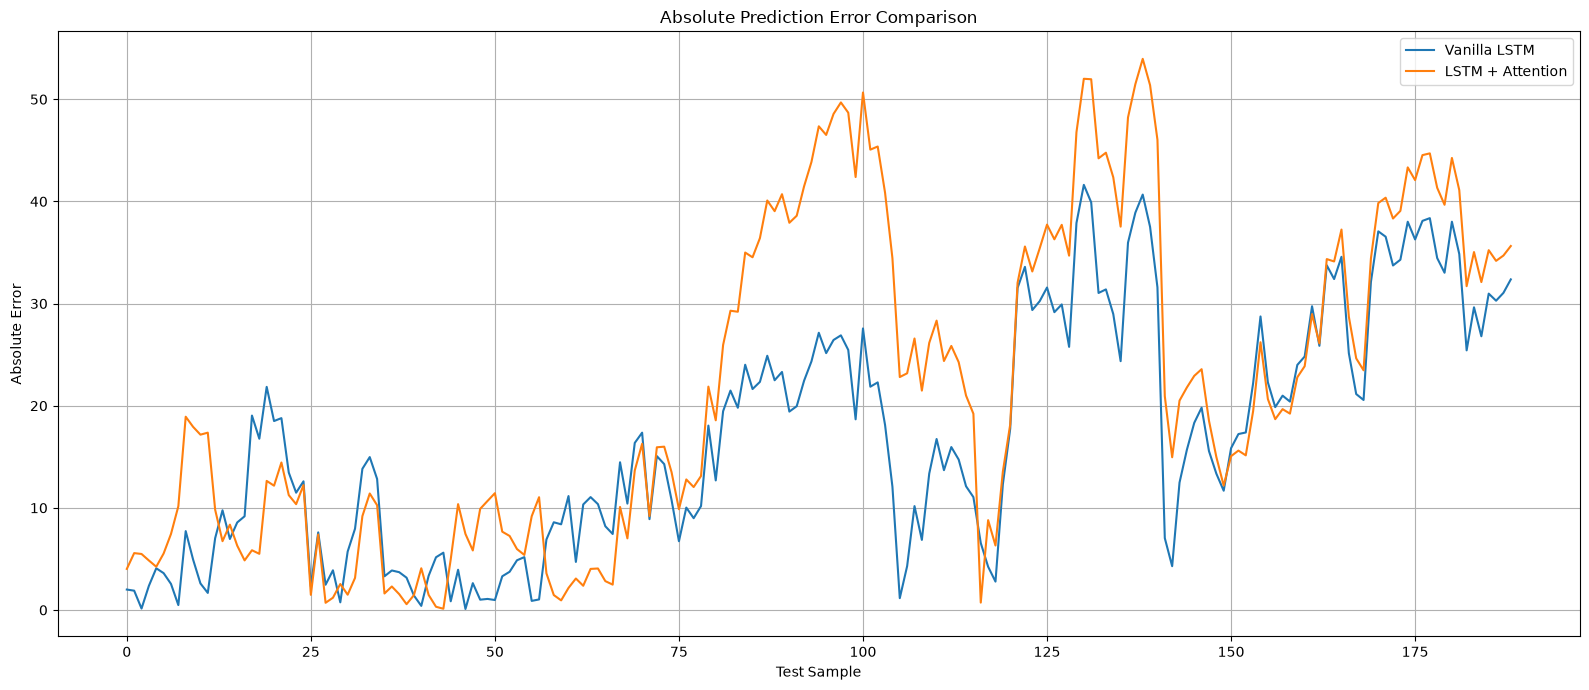

In [111]:
# ============================================================
# CELL 85 - ABSOLUTE ERROR COMPARISON
# ============================================================

evaluation_df["Vanilla_Absolute_Error"] = (
    evaluation_df["Vanilla_Error"].abs()
)

evaluation_df["Attention_Absolute_Error"] = (
    evaluation_df["Attention_Error"].abs()
)

plt.figure(figsize=(16, 7))

plt.plot(
    evaluation_df["Vanilla_Absolute_Error"],
    label="Vanilla LSTM"
)

plt.plot(
    evaluation_df["Attention_Absolute_Error"],
    label="LSTM + Attention"
)

plt.title(
    "Absolute Prediction Error Comparison"
)

plt.xlabel("Test Sample")
plt.ylabel("Absolute Error")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [112]:
# ============================================================
# CELL 86 - DIRECTIONAL ACCURACY
# ============================================================

actual_direction = (
    np.diff(actual_prices) > 0
)

vanilla_direction = (
    np.diff(predicted_prices) > 0
)

attention_direction = (
    np.diff(attention_predicted_prices) > 0
)

vanilla_directional_accuracy = (
    np.mean(
        actual_direction ==
        vanilla_direction
    )
) * 100

attention_directional_accuracy = (
    np.mean(
        actual_direction ==
        attention_direction
    )
) * 100

print("=" * 60)
print("DIRECTIONAL ACCURACY")
print("=" * 60)

print(
    f"Vanilla LSTM      : "
    f"{vanilla_directional_accuracy:.2f}%"
)

print(
    f"LSTM + Attention  : "
    f"{attention_directional_accuracy:.2f}%"
)

DIRECTIONAL ACCURACY
Vanilla LSTM      : 46.81%
LSTM + Attention  : 51.60%


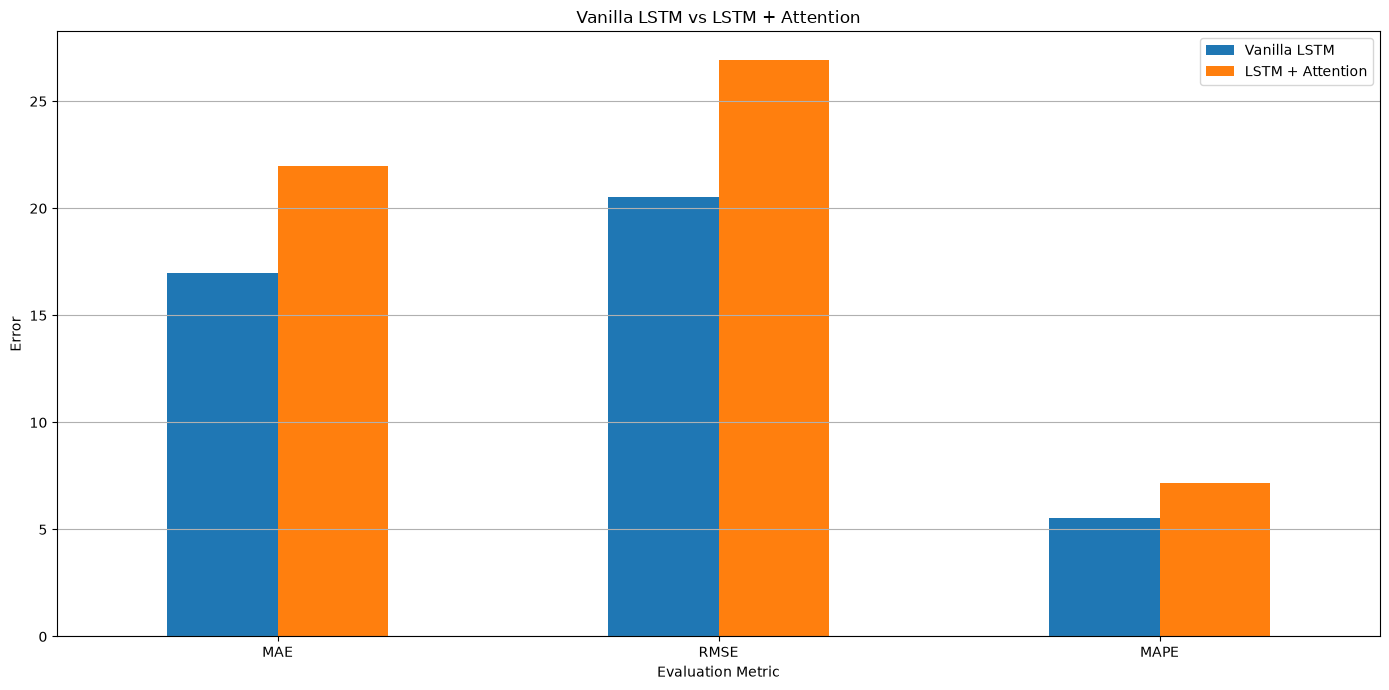

In [113]:
# ============================================================
# CELL 87 - MODEL METRICS BAR CHART
# ============================================================

metrics_for_plot = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "MAPE"
    ],

    "Vanilla LSTM": [
        mae,
        rmse,
        mape
    ],

    "LSTM + Attention": [
        attention_mae,
        attention_rmse,
        attention_mape
    ]
})

metrics_for_plot.set_index(
    "Metric"
).plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title(
    "Vanilla LSTM vs LSTM + Attention"
)

plt.xlabel("Evaluation Metric")
plt.ylabel("Error")

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.tight_layout()
plt.show()

In [114]:
# ============================================================
# CELL 88 - BUILD ATTENTION INSPECTION MODEL
# ============================================================

# Find the LSTM layer
lstm_layer = None

for layer in attention_model.layers:

    if isinstance(layer, LSTM):

        lstm_layer = layer
        break


# Find the attention layer
attention_layer = None

for layer in attention_model.layers:

    if isinstance(layer, TemporalAttention):

        attention_layer = layer
        break


print("LSTM layer found:")
print(lstm_layer.name)

print("\nAttention layer found:")
print(attention_layer.name)

LSTM layer found:
lstm_1

Attention layer found:
temporal_attention


In [115]:
# ============================================================
# CELL 89 - EXTRACT ATTENTION WEIGHTS
# ============================================================

def get_attention_weights(
    model,
    input_data
):
    """
    Extract temporal attention weights
    from the trained LSTM + Attention model.
    """

    # Locate layers
    lstm_layer = None
    attention_layer = None

    for layer in model.layers:

        if isinstance(layer, LSTM):
            lstm_layer = layer

        if isinstance(layer, TemporalAttention):
            attention_layer = layer

    # Get LSTM output
    lstm_outputs = lstm_layer(
        input_data
    )

    # Get attention parameters
    W = attention_layer.W
    b = attention_layer.b

    # Calculate scores
    scores = tf.nn.tanh(
        tf.matmul(
            lstm_outputs,
            W
        ) + b
    )

    # Calculate attention weights
    weights = tf.nn.softmax(
        scores,
        axis=1
    )

    return weights.numpy()

In [116]:
# ============================================================
# CELL 90 - ATTENTION WEIGHTS FOR ONE TEST SAMPLE
# ============================================================

sample_index = 0

sample_input = X_test[
    sample_index:sample_index + 1
]

sample_attention = get_attention_weights(
    attention_model,
    sample_input
)

sample_attention = sample_attention[
    0
].reshape(-1)

print(
    "Attention weights shape:",
    sample_attention.shape
)

print("\nFirst 10 attention weights:")

print(
    sample_attention[:10]
)

Attention weights shape: (60,)

First 10 attention weights:
[0.01392425 0.01412315 0.01443011 0.01476494 0.01506394 0.01532695
 0.01543702 0.01569332 0.01583982 0.01598931]


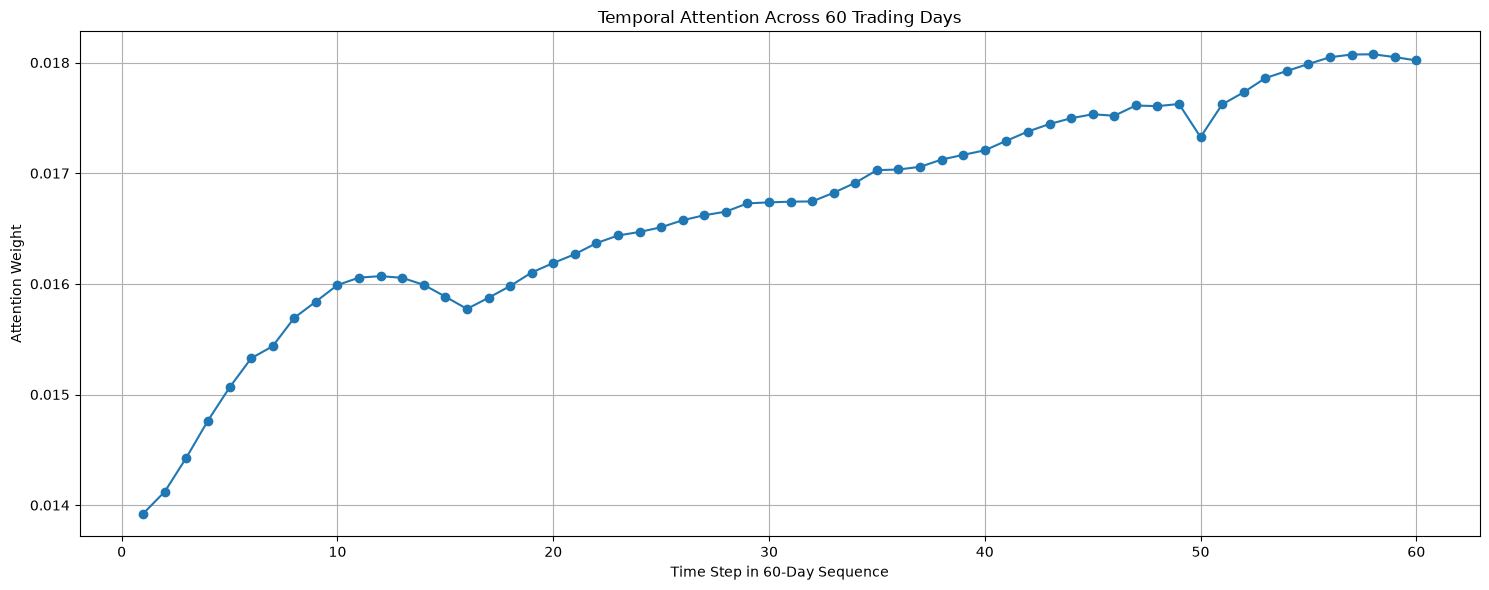

In [117]:
# ============================================================
# CELL 91 - ATTENTION WEIGHT VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    range(1, SEQUENCE_LENGTH + 1),
    sample_attention,
    marker="o"
)

plt.title(
    "Temporal Attention Across 60 Trading Days"
)

plt.xlabel(
    "Time Step in 60-Day Sequence"
)

plt.ylabel(
    "Attention Weight"
)

plt.grid(True)

plt.tight_layout()
plt.show()

In [118]:
# ============================================================
# CELL 92 - AVERAGE ATTENTION ACROSS TEST DATA
# ============================================================

attention_sample_count = min(
    200,
    len(X_test)
)

attention_subset = X_test[
    :attention_sample_count
]

all_attention_weights = (
    get_attention_weights(
        attention_model,
        attention_subset
    )
)

average_attention = (
    all_attention_weights.mean(
        axis=0
    ).reshape(-1)
)

print(
    "Average attention shape:",
    average_attention.shape
)

Average attention shape: (60,)


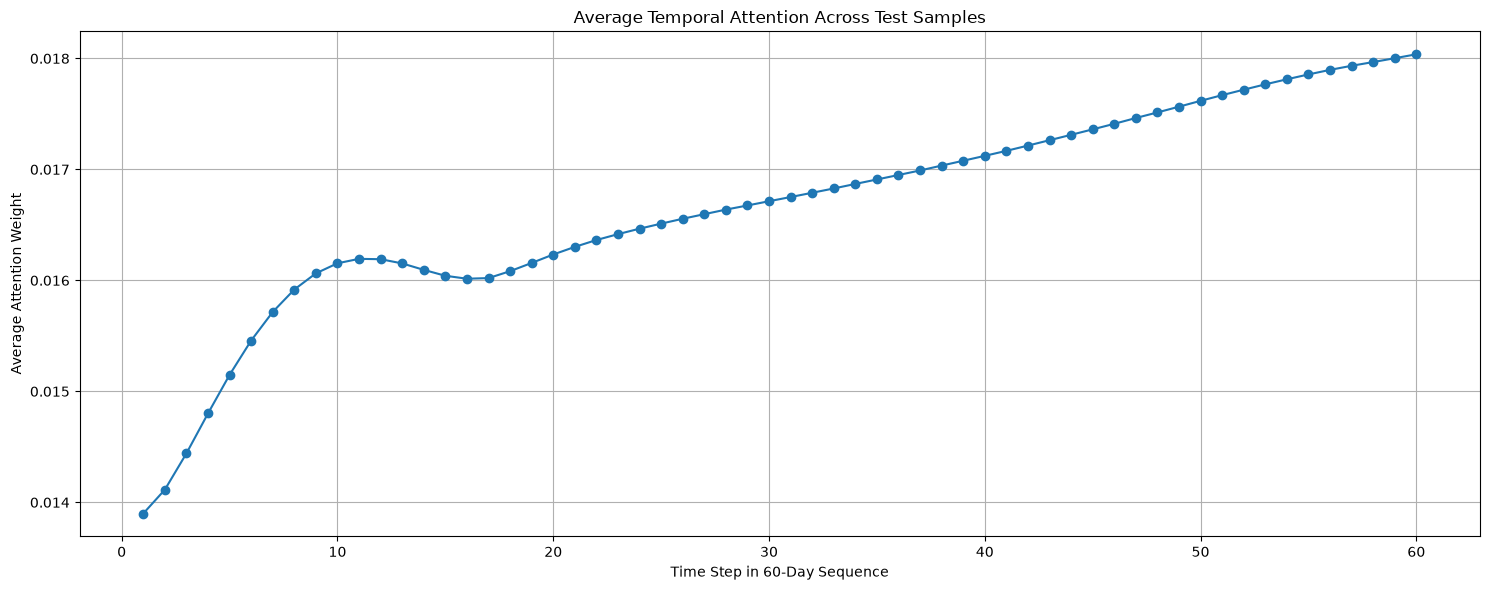

In [119]:
# ============================================================
# CELL 93 - AVERAGE ATTENTION VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    range(1, SEQUENCE_LENGTH + 1),
    average_attention,
    marker="o"
)

plt.title(
    "Average Temporal Attention Across Test Samples"
)

plt.xlabel(
    "Time Step in 60-Day Sequence"
)

plt.ylabel(
    "Average Attention Weight"
)

plt.grid(True)

plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# CELL 94 - TOP ATTENDED TIME STEPS
# ============================================================

top_indices = np.argsort(
    average_attention
)[::-1][:10]

top_attention_df = pd.DataFrame({

    "Time Step": top_indices + 1,

    "Attention Weight":
        average_attention[top_indices]

})

display(
    top_attention_df
)

,Time Step,Attention Weight
0,60,0.018037
1,59,0.018002
2,58,0.017967
3,57,0.017934
4,56,0.017897
5,55,0.017856
6,54,0.017812
7,53,0.017766
8,52,0.017718
9,51,0.017669


In [121]:
# ============================================================
# CELL 95 - FINAL EVALUATION SUMMARY
# ============================================================

final_evaluation = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "MAPE (%)",
        "Directional Accuracy (%)"
    ],

    "Vanilla LSTM": [
        mae,
        rmse,
        mape,
        vanilla_directional_accuracy
    ],

    "LSTM + Attention": [
        attention_mae,
        attention_rmse,
        attention_mape,
        attention_directional_accuracy
    ]
})

display(
    final_evaluation.style.format({
        "Vanilla LSTM": "{:.4f}",
        "LSTM + Attention": "{:.4f}"
    })
)

,Metric,Vanilla LSTM,LSTM + Attention
0,MAE,16.9822,21.9954
1,RMSE,20.5372,26.9190
2,MAPE (%),5.5404,7.1798
3,Directional Accuracy (%),46.8085,51.5957


In [122]:
# ============================================================
# CELL 96 - SAVE FINAL EVALUATION
# ============================================================

final_evaluation_path = os.path.join(
    "results",
    "AAPL_final_evaluation.csv"
)

final_evaluation.to_csv(
    final_evaluation_path,
    index=False
)

print(
    "Final evaluation saved:"
)

print(
    final_evaluation_path
)

Final evaluation saved:
results\AAPL_final_evaluation.csv


In [123]:
# ============================================================
# CELL 97 - SAVE PREDICTION DATA
# ============================================================

prediction_data_path = os.path.join(
    "results",
    "AAPL_prediction_comparison.csv"
)

evaluation_df.to_csv(
    prediction_data_path,
    index=False
)

print(
    "Prediction comparison saved:"
)

print(
    prediction_data_path
)

Prediction comparison saved:
results\AAPL_prediction_comparison.csv


In [124]:
# ============================================================
# CELL 98 - STEP 7 HEALTH CHECK
# ============================================================

print("=" * 60)
print("STEP 7 - EVALUATION & VISUALIZATION HEALTH CHECK")
print("=" * 60)

checks = {

    "Evaluation dataframe created":
        len(evaluation_df) > 0,

    "MAE comparison calculated":
        np.isfinite(mae) and
        np.isfinite(attention_mae),

    "RMSE comparison calculated":
        np.isfinite(rmse) and
        np.isfinite(attention_rmse),

    "MAPE comparison calculated":
        np.isfinite(mape) and
        np.isfinite(attention_mape),

    "Directional accuracy calculated":
        np.isfinite(
            vanilla_directional_accuracy
        ) and
        np.isfinite(
            attention_directional_accuracy
        ),

    "Attention weights extracted":
        len(average_attention) ==
        SEQUENCE_LENGTH,

    "Final evaluation saved":
        os.path.exists(
            final_evaluation_path
        ),

    "Prediction data saved":
        os.path.exists(
            prediction_data_path
        )
}

for check, status in checks.items():

    symbol = "✓" if status else "✗"

    print(
        f"{symbol} {check}"
    )

print("\n" + "=" * 60)
print("STEP 7 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 7 - EVALUATION & VISUALIZATION HEALTH CHECK
✓ Evaluation dataframe created
✓ MAE comparison calculated
✓ RMSE comparison calculated
✓ MAPE comparison calculated
✓ Directional accuracy calculated
✓ Attention weights extracted
✓ Final evaluation saved
✓ Prediction data saved

STEP 7 COMPLETED SUCCESSFULLY


**Dynamic Prediction Engine + Model Caching**

In [130]:
# Cell 99: Dynamic model and scaler file paths

def ticker_to_filename(ticker):
    ticker = str(ticker).strip().upper()
    return ticker.replace(".", "_").replace("^", "_")


def get_model_paths(ticker):
    safe_ticker = ticker_to_filename(ticker)

    paths = {
        "vanilla_model": os.path.join(
            "models", f"{safe_ticker}_vanilla_lstm.keras"
        ),
        "attention_model": os.path.join(
            "models", f"{safe_ticker}_lstm_attention.keras"
        ),
        "scaler": os.path.join(
            "scalers", f"{safe_ticker}_scaler.joblib"
        ),
        "results": os.path.join(
            "results", f"{safe_ticker}_dynamic_results.json"
        )
    }

    return paths


# Test
paths = get_model_paths("AAPL")
paths

{'vanilla_model': 'models\\AAPL_vanilla_lstm.keras',
 'attention_model': 'models\\AAPL_lstm_attention.keras',
 'scaler': 'scalers\\AAPL_scaler.joblib',
 'results': 'results\\AAPL_dynamic_results.json'}

In [131]:
# Cell 100: Scaler save/load functions

def save_scaler(scaler, ticker):
    paths = get_model_paths(ticker)

    os.makedirs("scalers", exist_ok=True)

    joblib.dump(scaler, paths["scaler"])

    print(f"Scaler saved: {paths['scaler']}")


def load_scaler(ticker):
    paths = get_model_paths(ticker)

    if not os.path.exists(paths["scaler"]):
        return None

    scaler = joblib.load(paths["scaler"])

    print(f"Scaler loaded: {paths['scaler']}")

    return scaler

In [132]:
# Cell 101: Model cache checker

def models_exist(ticker):
    paths = get_model_paths(ticker)

    vanilla_exists = os.path.exists(paths["vanilla_model"])
    attention_exists = os.path.exists(paths["attention_model"])
    scaler_exists = os.path.exists(paths["scaler"])

    return vanilla_exists and attention_exists and scaler_exists


# Test
print("AAPL models cached:", models_exist("AAPL"))

AAPL models cached: False


In [133]:
# Cell 101A: Save the existing AAPL scaler

save_scaler(scaler, "AAPL")

print("\nAAPL scaler has been saved successfully.")

Scaler saved: scalers\AAPL_scaler.joblib

AAPL scaler has been saved successfully.


In [134]:
print("AAPL models cached:", models_exist("AAPL"))

AAPL models cached: True


In [135]:
# Cell 102: Load cached models

def load_cached_models(ticker):
    paths = get_model_paths(ticker)

    if not models_exist(ticker):
        raise FileNotFoundError(
            f"Trained models for {ticker} were not found."
        )

    vanilla_model = tf.keras.models.load_model(
        paths["vanilla_model"]
    )

    attention_model = tf.keras.models.load_model(
        paths["attention_model"],
        custom_objects={
            "TemporalAttention": TemporalAttention
        }
    )

    scaler = load_scaler(ticker)

    print(f"Models loaded successfully for {ticker}")

    return vanilla_model, attention_model, scaler

In [136]:
# Cell 103: Train models dynamically for any ticker

def train_models_for_ticker(
    ticker,
    period="5y",
    force_retrain=False
):
    
    ticker = str(ticker).strip().upper()

    # Check if models already exist
    if models_exist(ticker) and not force_retrain:
        print(f"Cached models found for {ticker}.")
        print("Loading existing models instead of retraining...")

        return load_cached_models(ticker)

    print("=" * 70)
    print(f"TRAINING MODELS FOR: {ticker}")
    print("=" * 70)

    # Step 1: Download stock data
    print("\n1. Downloading Yahoo Finance data...")

    data = get_stock_data(
        ticker=ticker,
        period=period
    )

    print(f"Downloaded {len(data)} rows.")

    # Step 2: Preprocess
    print("\n2. Preprocessing data...")

    (
        X_train,
        y_train,
        X_validation,
        y_validation,
        X_test,
        y_test,
        scaler
    ) = preprocess_stock_data(data)

    print(f"Training samples: {len(X_train)}")
    print(f"Validation samples: {len(X_validation)}")
    print(f"Testing samples: {len(X_test)}")

    # Step 3: Build Vanilla LSTM
    print("\n3. Building Vanilla LSTM...")

    vanilla_model = build_vanilla_lstm()

    vanilla_early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True
    )

    # Step 4: Train Vanilla LSTM
    print("\n4. Training Vanilla LSTM...")

    vanilla_model.fit(
        X_train,
        y_train,
        validation_data=(X_validation, y_validation),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[vanilla_early_stopping],
        shuffle=False,
        verbose=1
    )

    # Step 5: Build Attention model
    print("\n5. Building LSTM + Attention model...")

    attention_model = build_lstm_attention_model()

    attention_early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True
    )

    # Step 6: Train Attention model
    print("\n6. Training LSTM + Attention model...")

    attention_model.fit(
        X_train,
        y_train,
        validation_data=(X_validation, y_validation),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[attention_early_stopping],
        shuffle=False,
        verbose=1
    )

    # Step 7: Save models
    paths = get_model_paths(ticker)

    os.makedirs("models", exist_ok=True)

    vanilla_model.save(paths["vanilla_model"])
    attention_model.save(paths["attention_model"])

    # Step 8: Save scaler
    save_scaler(scaler, ticker)

    print("\nModels and scaler saved successfully.")

    return vanilla_model, attention_model, scaler

In [144]:
# Cell 103A: Define training configuration variables

LSTM_UNITS = PROJECT_CONFIG["lstm_units"]
DROPOUT_RATE = PROJECT_CONFIG["dropout"]
DENSE_UNITS = PROJECT_CONFIG["dense_units"]

EPOCHS = PROJECT_CONFIG["epochs"]
BATCH_SIZE = PROJECT_CONFIG["batch_size"]

EARLY_STOPPING_PATIENCE = PROJECT_CONFIG["early_stopping_patience"]

print("Training configuration loaded successfully.")
print("LSTM Units:", LSTM_UNITS)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)

Training configuration loaded successfully.
LSTM Units: 64
Epochs: 30
Batch Size: 64
Early Stopping Patience: 5


In [137]:
# Cell 104: Test dynamic model loading

vanilla_model, attention_model, scaler = train_models_for_ticker(
    "AAPL"
)

print("\nDynamic model engine is working.")

Cached models found for AAPL.
Loading existing models instead of retraining...
Scaler loaded: scalers\AAPL_scaler.joblib
Models loaded successfully for AAPL

Dynamic model engine is working.


In [138]:
# Cell 105: Prepare latest sequence

def prepare_latest_sequence(data, scaler):
    
    latest_data = data[FEATURE_COLUMNS].copy()

    if len(latest_data) < SEQUENCE_LENGTH:
        raise ValueError(
            f"At least {SEQUENCE_LENGTH} rows are required "
            f"for prediction."
        )

    scaled_data = scaler.transform(latest_data)

    latest_sequence = scaled_data[-SEQUENCE_LENGTH:]

    latest_sequence = np.expand_dims(
        latest_sequence,
        axis=0
    )

    return latest_sequence

In [139]:
# Cell 106: Next-day prediction function

def predict_next_day(
    ticker,
    period="5y",
    force_retrain=False
):
    
    ticker = str(ticker).strip().upper()

    print("=" * 70)
    print(f"NEXT-DAY PREDICTION: {ticker}")
    print("=" * 70)

    # Get latest data
    data = get_stock_data(
        ticker=ticker,
        period=period
    )

    # Load or train models
    vanilla_model, attention_model, scaler = train_models_for_ticker(
        ticker=ticker,
        period=period,
        force_retrain=force_retrain
    )

    # Prepare latest 60-day sequence
    latest_sequence = prepare_latest_sequence(
        data,
        scaler
    )

    # Make predictions
    vanilla_prediction_scaled = vanilla_model.predict(
        latest_sequence,
        verbose=0
    )

    attention_prediction_scaled = attention_model.predict(
        latest_sequence,
        verbose=0
    )

    # Convert predictions back to actual price
    vanilla_prediction = inverse_transform_close(
        vanilla_prediction_scaled,
        scaler
    )[0]

    attention_prediction = inverse_transform_close(
        attention_prediction_scaled,
        scaler
    )[0]

    # Current closing price
    current_price = float(data[TARGET_COLUMN].iloc[-1])

    # Percentage changes
    vanilla_change = (
        (vanilla_prediction - current_price)
        / current_price
    ) * 100

    attention_change = (
        (attention_prediction - current_price)
        / current_price
    ) * 100

    # Direction
    vanilla_direction = (
        "UP" if vanilla_prediction > current_price
        else "DOWN"
    )

    attention_direction = (
        "UP" if attention_prediction > current_price
        else "DOWN"
    )

    prediction_result = {
        "ticker": ticker,
        "last_date": str(data.index[-1].date()),
        "current_price": current_price,

        "vanilla_lstm_prediction": float(vanilla_prediction),
        "vanilla_expected_change_percent": float(vanilla_change),
        "vanilla_direction": vanilla_direction,

        "attention_prediction": float(attention_prediction),
        "attention_expected_change_percent": float(attention_change),
        "attention_direction": attention_direction
    }

    return prediction_result

In [140]:
# Cell 107: Test next-day prediction

prediction = predict_next_day("AAPL")

prediction

NEXT-DAY PREDICTION: AAPL
Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : AAPL
Rows         : 1,255
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']
Cached models found for AAPL.
Loading existing models instead of retraining...
Scaler loaded: scalers\AAPL_scaler.joblib
Models loaded successfully for AAPL


{'ticker': 'AAPL',
 'last_date': '2026-10-07',
 'current_price': 335.4700012207031,
 'vanilla_lstm_prediction': 302.43604831008906,
 'vanilla_expected_change_percent': -9.847066143145621,
 'vanilla_direction': 'DOWN',
 'attention_prediction': 299.3548246092778,
 'attention_expected_change_percent': -10.765545795454134,
 'attention_direction': 'DOWN'}

In [141]:
# Cell 108: Display prediction results

def display_prediction_result(prediction):
    
    print("\n" + "=" * 60)
    print(f"STOCK PREDICTION RESULT — {prediction['ticker']}")
    print("=" * 60)

    print(f"\nLast available trading date : {prediction['last_date']}")
    print(
        f"Current closing price      : "
        f"{prediction['current_price']:.2f}"
    )

    print("\n--- Vanilla LSTM ---")

    print(
        f"Predicted next-day price   : "
        f"{prediction['vanilla_lstm_prediction']:.2f}"
    )

    print(
        f"Expected change            : "
        f"{prediction['vanilla_expected_change_percent']:.2f}%"
    )

    print(
        f"Predicted direction        : "
        f"{prediction['vanilla_direction']}"
    )

    print("\n--- LSTM + Attention ---")

    print(
        f"Predicted next-day price   : "
        f"{prediction['attention_prediction']:.2f}"
    )

    print(
        f"Expected change            : "
        f"{prediction['attention_expected_change_percent']:.2f}%"
    )

    print(
        f"Predicted direction        : "
        f"{prediction['attention_direction']}"
    )

    print("\n" + "=" * 60)

In [142]:
# Cell 109: Display AAPL prediction

display_prediction_result(prediction)


STOCK PREDICTION RESULT — AAPL

Last available trading date : 2026-10-07
Current closing price      : 335.47

--- Vanilla LSTM ---
Predicted next-day price   : 302.44
Expected change            : -9.85%
Predicted direction        : DOWN

--- LSTM + Attention ---
Predicted next-day price   : 299.35
Expected change            : -10.77%
Predicted direction        : DOWN



In [145]:
prediction_reliance = predict_next_day("RELIANCE.NS")

display_prediction_result(prediction_reliance)

NEXT-DAY PREDICTION: RELIANCE.NS
Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : RELIANCE.NS
Rows         : 1,241
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']
TRAINING MODELS FOR: RELIANCE.NS

1. Downloading Yahoo Finance data...
Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : RELIANCE.NS
Rows         : 1,241
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']
Downloaded 1241 rows.

2. Preprocessing data...
Time-Series Split
Training   : 868 rows (69.9%)
Validation : 186 rows (15.0%)
Testing    : 187 rows (15.1%)

Date ranges:
Training   : 2021-10-07 → 2025-04-11
Validation : 2025-04-15 → 2026-01-09
Testing    : 2026-01-12 → 2026-10-07
Training samples: 808
Validation samples: 186
Testing samples: 187

3. Building Vanilla LSTM...

4. Training Vanilla LSTM...
Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 216ms/step - loss: 0.01

In [146]:
# Cell 111: Verify model caching

prediction_reliance_cached = predict_next_day(
    "RELIANCE.NS"
)

display_prediction_result(
    prediction_reliance_cached
)

NEXT-DAY PREDICTION: RELIANCE.NS
Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : RELIANCE.NS
Rows         : 1,241
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']
Cached models found for RELIANCE.NS.
Loading existing models instead of retraining...
Scaler loaded: scalers\RELIANCE_NS_scaler.joblib
Models loaded successfully for RELIANCE.NS

STOCK PREDICTION RESULT — RELIANCE.NS

Last available trading date : 2026-10-07
Current closing price      : 1207.70

--- Vanilla LSTM ---
Predicted next-day price   : 1196.88
Expected change            : -0.90%
Predicted direction        : DOWN

--- LSTM + Attention ---
Predicted next-day price   : 1330.09
Expected change            : 10.13%
Predicted direction        : UP



In [147]:
# Cell 112: Main prediction interface

def predict_stock(ticker, period="5y"):
    
    ticker = str(ticker).strip().upper()

    # Validate ticker against company catalogue
    company = get_company_by_ticker(ticker)

    if company is None:
        raise ValueError(
            f"{ticker} is not available in the company catalogue."
        )

    result = predict_next_day(
        ticker=ticker,
        period=period
    )

    # Add company information
    result["company_name"] = company["name"]
    result["country"] = company["country"]
    result["exchange"] = company["exchange"]

    return result

In [148]:
# Cell 113: Final dynamic prediction test

result = predict_stock("AAPL")

display_prediction_result(result)

print("\nCompany Information:")
print("Company :", result["company_name"])
print("Country :", result["country"])
print("Exchange:", result["exchange"])

NEXT-DAY PREDICTION: AAPL
Period: 5y
Interval: 1d

Data downloaded successfully.
Ticker       : AAPL
Rows         : 1,255
Start date   : 2021-10-07
End date     : 2026-10-07
Columns      : ['Open', 'High', 'Low', 'Close', 'Volume']
Cached models found for AAPL.
Loading existing models instead of retraining...
Scaler loaded: scalers\AAPL_scaler.joblib
Models loaded successfully for AAPL

STOCK PREDICTION RESULT — AAPL

Last available trading date : 2026-10-07
Current closing price      : 335.61

--- Vanilla LSTM ---
Predicted next-day price   : 302.44
Expected change            : -9.88%
Predicted direction        : DOWN

--- LSTM + Attention ---
Predicted next-day price   : 299.35
Expected change            : -10.80%
Predicted direction        : DOWN


Company Information:
Company : Apple Inc.
Country : USA
Exchange: NASDAQ
